# Tissue contexts relevant to 5-FU response

5-fluorouracil (5-FU) is the backbone of chemotherapy for colorectal cancer. Experimental models have identified several tissue processes that change how well it works. This notebook asks two questions:
- Do the multicellular programs, the MuVI factors of `MOFACell.ipynb`, capture these processes?
- Do combinations of programs point to tumours in which different processes would limit or support 5-FU?

The samples are resections, most of them taken at diagnosis before any treatment. Prior treatment cannot be ruled out for every sample. The analysis describes the tissue at the time of resection. It does not model a treatment effect or predict response.

## Processes
Each process is measured through the panel markers that come closest to the mechanism found in experiments.

| Process | Measured here | Mechanism in experimental models | Expected direction |
|---|---|---|---|
| A, mitochondrial machinery | CytC, ATP5A and CS in epithelial cells | Cells that survive 5-FU raise their mitochondrial content, and blocking complex I makes them sensitive again (Moss et al. 2026) | Higher: resistance |
| B, hypoxia-associated myeloid context | Macrophages and monocytes, CA9-high epithelial cells, and how close the two are | Hypoxia raises dihydropyrimidine dehydrogenase (DPD) in macrophages and monocytes. DPD breaks down 5-FU before it reaches the tumour cells (Malier et al. 2021, Gharzeddine et al. 2024) | More myeloid cells in hypoxic tissue: resistance |
| C, glutamine use | GLS and ASCT2 in epithelial cells | Glutaminolysis driven by the transporter SLC25A22 reduces 5-FU sensitivity in KRAS-mutant cells (Wong et al. 2020) | Higher: resistance |
| D, glycolytic machinery | GLUT1, PKM2 and LDH in epithelial cells | Glycolysis supports 5-FU resistance in TRPC5-high cells (Wang et al. 2018) | Higher: resistance |
| Proliferation | Ki67 in epithelial cells | 5-FU blocks thymidylate synthase and DNA synthesis, so dividing cells are its main target | Higher: sensitivity |
| Mismatch repair | Clinical MSI status | Mismatch repair proteins recognise 5-FU built into DNA and trigger cell death, so cells without mismatch repair tolerate 5-FU better (Carethers et al. 1999). Patients with MSI colon cancer drew no benefit from adjuvant 5-FU alone (Ribic et al. 2003, Sargent et al. 2010) | MSI: resistance |

DPD, SLC25A22, TRPC5 and metabolic flux are not measured. The LDH antibody binds LDHA, LDHB and LDHC. LDHA should be the most abundant in these tissues.

## Cells and patients
Epithelial cells are the cells annotated `Cancer_cell` in the consensus annotation. They are PanCK-positive epithelial cells in tumour cores. No marker of the panel separates tumour cells from residual benign epithelium, so this notebook calls them epithelial cells. Their Ki67 serves as an estimate of how aggressive the tumour is. Myeloid cells are CD68 macrophages, CD163 macrophages and monocytes, the populations in which DPD was described.

Each TMA core comes from a different patient. All statistics count each patient once and never treat cells as independent samples.

## Steps
1. **Decisions.** All thresholds are set before any result is computed.
2. **Data.** Cells, patients and the clinical annotations used in `MOFACell.ipynb`.
3. **Marker quality.** Where each marker is expressed, whether the markers of a process agree, and whether CA9 in myeloid cells can be trusted.
4. **Readouts per patient.** Each process is measured from the cells, independently of MuVI, with checks of what drives the readouts.
5. **Processes in the factors.** Which cell types carry the process markers in the loadings, and which factors follow each readout.
6. **Factor 6 against Factor 9.** The two factors linked to the most processes, combined, with their process profiles and clinical annotations.
7. **Therapeutic interpretation** of the combinations.

## Imports

In [1]:
import os
import numpy as np
import pandas as pd
import anndata as ad
import muon as mu
from plotnine import *
from mizani.bounds import squish
from scanpy.plotting.palettes import default_20
from scipy.spatial import cKDTree
from scipy.stats import spearmanr, rankdata, kruskal, wilcoxon
from statsmodels.stats.multitest import multipletests

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Decisions
Every choice that can change a result is set here, before any result is computed, so that none is tuned after seeing the data. Thresholds are relative to this cohort, and none is chosen with a clinical variable.

In [2]:
data_dir = "../../data/"
output_dir = data_dir + "therapeutic/"
figure_dir = "../../figures/therapeutic/"
os.makedirs(output_dir, exist_ok=True)
os.makedirs(figure_dir, exist_ok=True)

seed = 0
um_per_px = 400 / 1024  # 400 µm FOVs of 1024 pixels

# Cell populations
epithelial_label = "Cancer_cell"  # PanCK-positive epithelial cells of the tumour cores
myeloid_types = ["CD68_Macrophage", "CD163_Macrophage", "Monocyte"]
min_epithelial_cells = 20  # rule of the earlier analyses; all FOVs of the MuVI model pass it

# Markers of each process, measured in epithelial cells
markers = {
    "A": ["CytC", "ATP5A", "CS"],
    "C": ["GLS", "ASCT2", "GS"],  # GS synthesises glutamine and is never pooled with GLS
    "D": ["GLUT1", "PKM2", "LDH"],
}
# Markers are averaged into a composite only if every pair correlates at least this much across patients
composite_min_rho = 0.5
composite_markers = {"A": ["CytC", "ATP5A", "CS"], "C": ["GLS", "ASCT2"], "D": ["GLUT1", "PKM2", "LDH"]}

# An epithelial cell is CA9-high above this quantile of CA9 in all epithelial cells of the cohort.
# The other quantiles check that the cutoff does not drive the ranking of patients.
ca9_quantile = 0.75
ca9_quantiles_sensitivity = [0.5, 0.9]

# Radii of the spatial readouts, in pixels: the juxtaview and paraview of the MISTy features used by MuVI
radii_px = [40, 120]
min_myeloid_cells = 10  # per patient, for the localisation readout
min_cells_near_far = 5  # myeloid cells on each side, for the myeloid GLUT1 readout

# Combinations of Factors 6 and 9: each factor is split at this quantile of its scores across patients
factor_split_quantile = 0.5

# Uncertainty and multiple testing
n_bootstrap = 1000
fdr = 0.05

In [3]:
# Correlations and loadings go from orange for negative values to blue for positive values
def scale_fill_correlation(name="", limits=(-1, 1)):
    return scale_fill_gradient2(low="#FC8D62", mid="white", high="#6291FC", midpoint=0, limits=limits,
                                oob=squish, name=name)

# Palettes of the other notebooks: pT stages in purples as in MetabViz.ipynb and MOFACell.ipynb,
# pN stages in greens as in MOFACell.ipynb, MSI in reds as in MSI.ipynb.
# Cell types use the scanpy default palette in the category order of the consensus annotation, as in CellTypeViz.ipynb.
clinical_colors = {"pT1": "#f2f0f7", "pT2": "#cbc9e2", "pT3": "#9e9ac9", "pT4": "#6a51a3",
                   "pN0": "#e5f5e0", "pN1": "#a1d99b", "pN2": "#31a354",
                   "MSS": "#fee0d2", "MSI": "#fc9272"}

# Half violins with a white dot at the median, as in the lineage and metabolism notebooks
def half_violins(fill):
    return [geom_violin(aes(fill=fill), style="right", scale="width", width=1.25, size=0.3),
            stat_summary(fun_y=np.median, geom="point", color="white", size=1.5)]

## 2. Data
### Patients and factor scores
The MuVI model was fit on FOVs of tumour cores and of healthy colon, from sector E of the TMA. Only the tumour cores are kept, since the processes concern tumours. Factor scores are stored in the order of the FOVs of `celltype_features_with_functional_markers.h5mu`, as checked in `sampling/FactorActivity.ipynb`.

In [4]:
features = mu.read_h5mu(data_dir + "celltype_features_with_functional_markers.h5mu")
factor_order = [f"Factor {i}" for i in range(1, 11)]

scores = pd.read_csv(data_dir + "factor_scores.csv")
assert len(scores) == features.n_obs and (scores.Stage.values == features.obs.Stage.values).all()
scores.index = features.obs_names
patients = features.obs_names[features.obs.Stage != "Colon-no."]
scores = scores.loc[patients, factor_order]
print(len(patients), "tumour patients;", features.n_obs - len(patients), "healthy FOVs left out")

418 tumour patients; 5 healthy FOVs left out


/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:931: UserWarning: Cannot join columns with the same name because var_names are intersecting.
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


### Cells
The cell table holds the transformed marker intensities used throughout the project, the consensus cell types, the cell positions and the clinical annotations of each core.

In [5]:
marker_columns = ["CytC", "ATP5A", "CS", "GLS", "ASCT2", "GS", "GLUT1", "PKM2", "LDH", "CA9", "Ki67", "CPT1A"]
clinical_columns = {"pT": "pT group", "pN": "pN raw", "MSI": "MSI gesamt RED"}
cell_table = pd.read_csv(data_dir + "cell_table_with_types_stage.csv", low_memory=False,
                         usecols=["fov", "annotation_consensus", "centroid-0", "centroid-1", "area"]
                                 + marker_columns + list(clinical_columns.values()))
cells = cell_table[cell_table.fov.isin(patients)].rename(
    columns={"annotation_consensus": "cell_type", "centroid-0": "x", "centroid-1": "y"}).reset_index(drop=True)
cells["epithelial"] = cells.cell_type == epithelial_label
cells["myeloid"] = cells.cell_type.isin(myeloid_types)

n_epithelial = cells[cells.epithelial].groupby("fov").size().reindex(patients, fill_value=0)
assert (n_epithelial > min_epithelial_cells).all()
print(len(cells), "cells;", cells.epithelial.sum(), "epithelial cells;",
      "epithelial cells per patient from", n_epithelial.min(), "to", n_epithelial.max())
cells.cell_type.value_counts()

527835 cells; 256750 epithelial cells; epithelial cells per patient from 22 to 1893


cell_type
Cancer_cell          256750
Unclear               80881
CAF                   62774
Monocyte              26017
Endothelial_cell      25910
Neutrophil            17619
CD4_Tcell             12576
Other_immune_cell     12096
CD68_Macrophage        9207
CD163_Macrophage       8193
CD8_Tcell              5775
NK_cell                3621
APC                    3379
T_reg_cell             1705
B_cell                 1332
Name: count, dtype: int64

### Clinical annotations
`MOFACell.ipynb` tested the factors against three clinical annotations: pT, pN and MSI. This notebook uses the same definitions: the pT group, the pN stage from the raw annotation without its substage letter, and the overall MSI status. It does not test these associations again.

In [6]:
clinical_raw = cells.groupby("fov")[list(clinical_columns.values())].first().loc[patients]
clinical_raw.columns = list(clinical_columns)
clinical = pd.DataFrame({
    "pT": pd.Categorical(clinical_raw.pT, categories=["pT1", "pT2", "pT3", "pT4"]),
    "pN": pd.Categorical(clinical_raw.pN.str[:3], categories=["pN0", "pN1", "pN2"]),
    "MSI": pd.Categorical(clinical_raw.MSI.map({"stabil": "MSS", "instabil": "MSI"}), categories=["MSS", "MSI"]),
}, index=patients)
pd.DataFrame({"annotated patients": clinical.notna().sum(),
              "categories": [", ".join(f"{k} {v}" for k, v in clinical[c].value_counts(sort=False).items()) for c in clinical]})

,annotated patients,categories
pT,418,"pT1 18, pT2 85, pT3 218, pT4 97"
pN,416,"pN0 222, pN1 106, pN2 88"
MSI,331,"MSS 314, MSI 17"


## 3. Marker quality
A readout is only as good as its markers. Three checks come before any readout is computed:
- where each marker is expressed, since a readout of epithelial machinery carries most information for markers that are higher in epithelial cells than in the other cell types,
- whether the markers of a process agree, since only agreeing markers can be averaged,
- whether CA9 measured in myeloid cells can be read as myeloid hypoxia.

### Where the markers are expressed
Each half violin shows the distribution, across patients, of the median of a marker in one cell type. White dots mark the median patient.

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x interval

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x interval

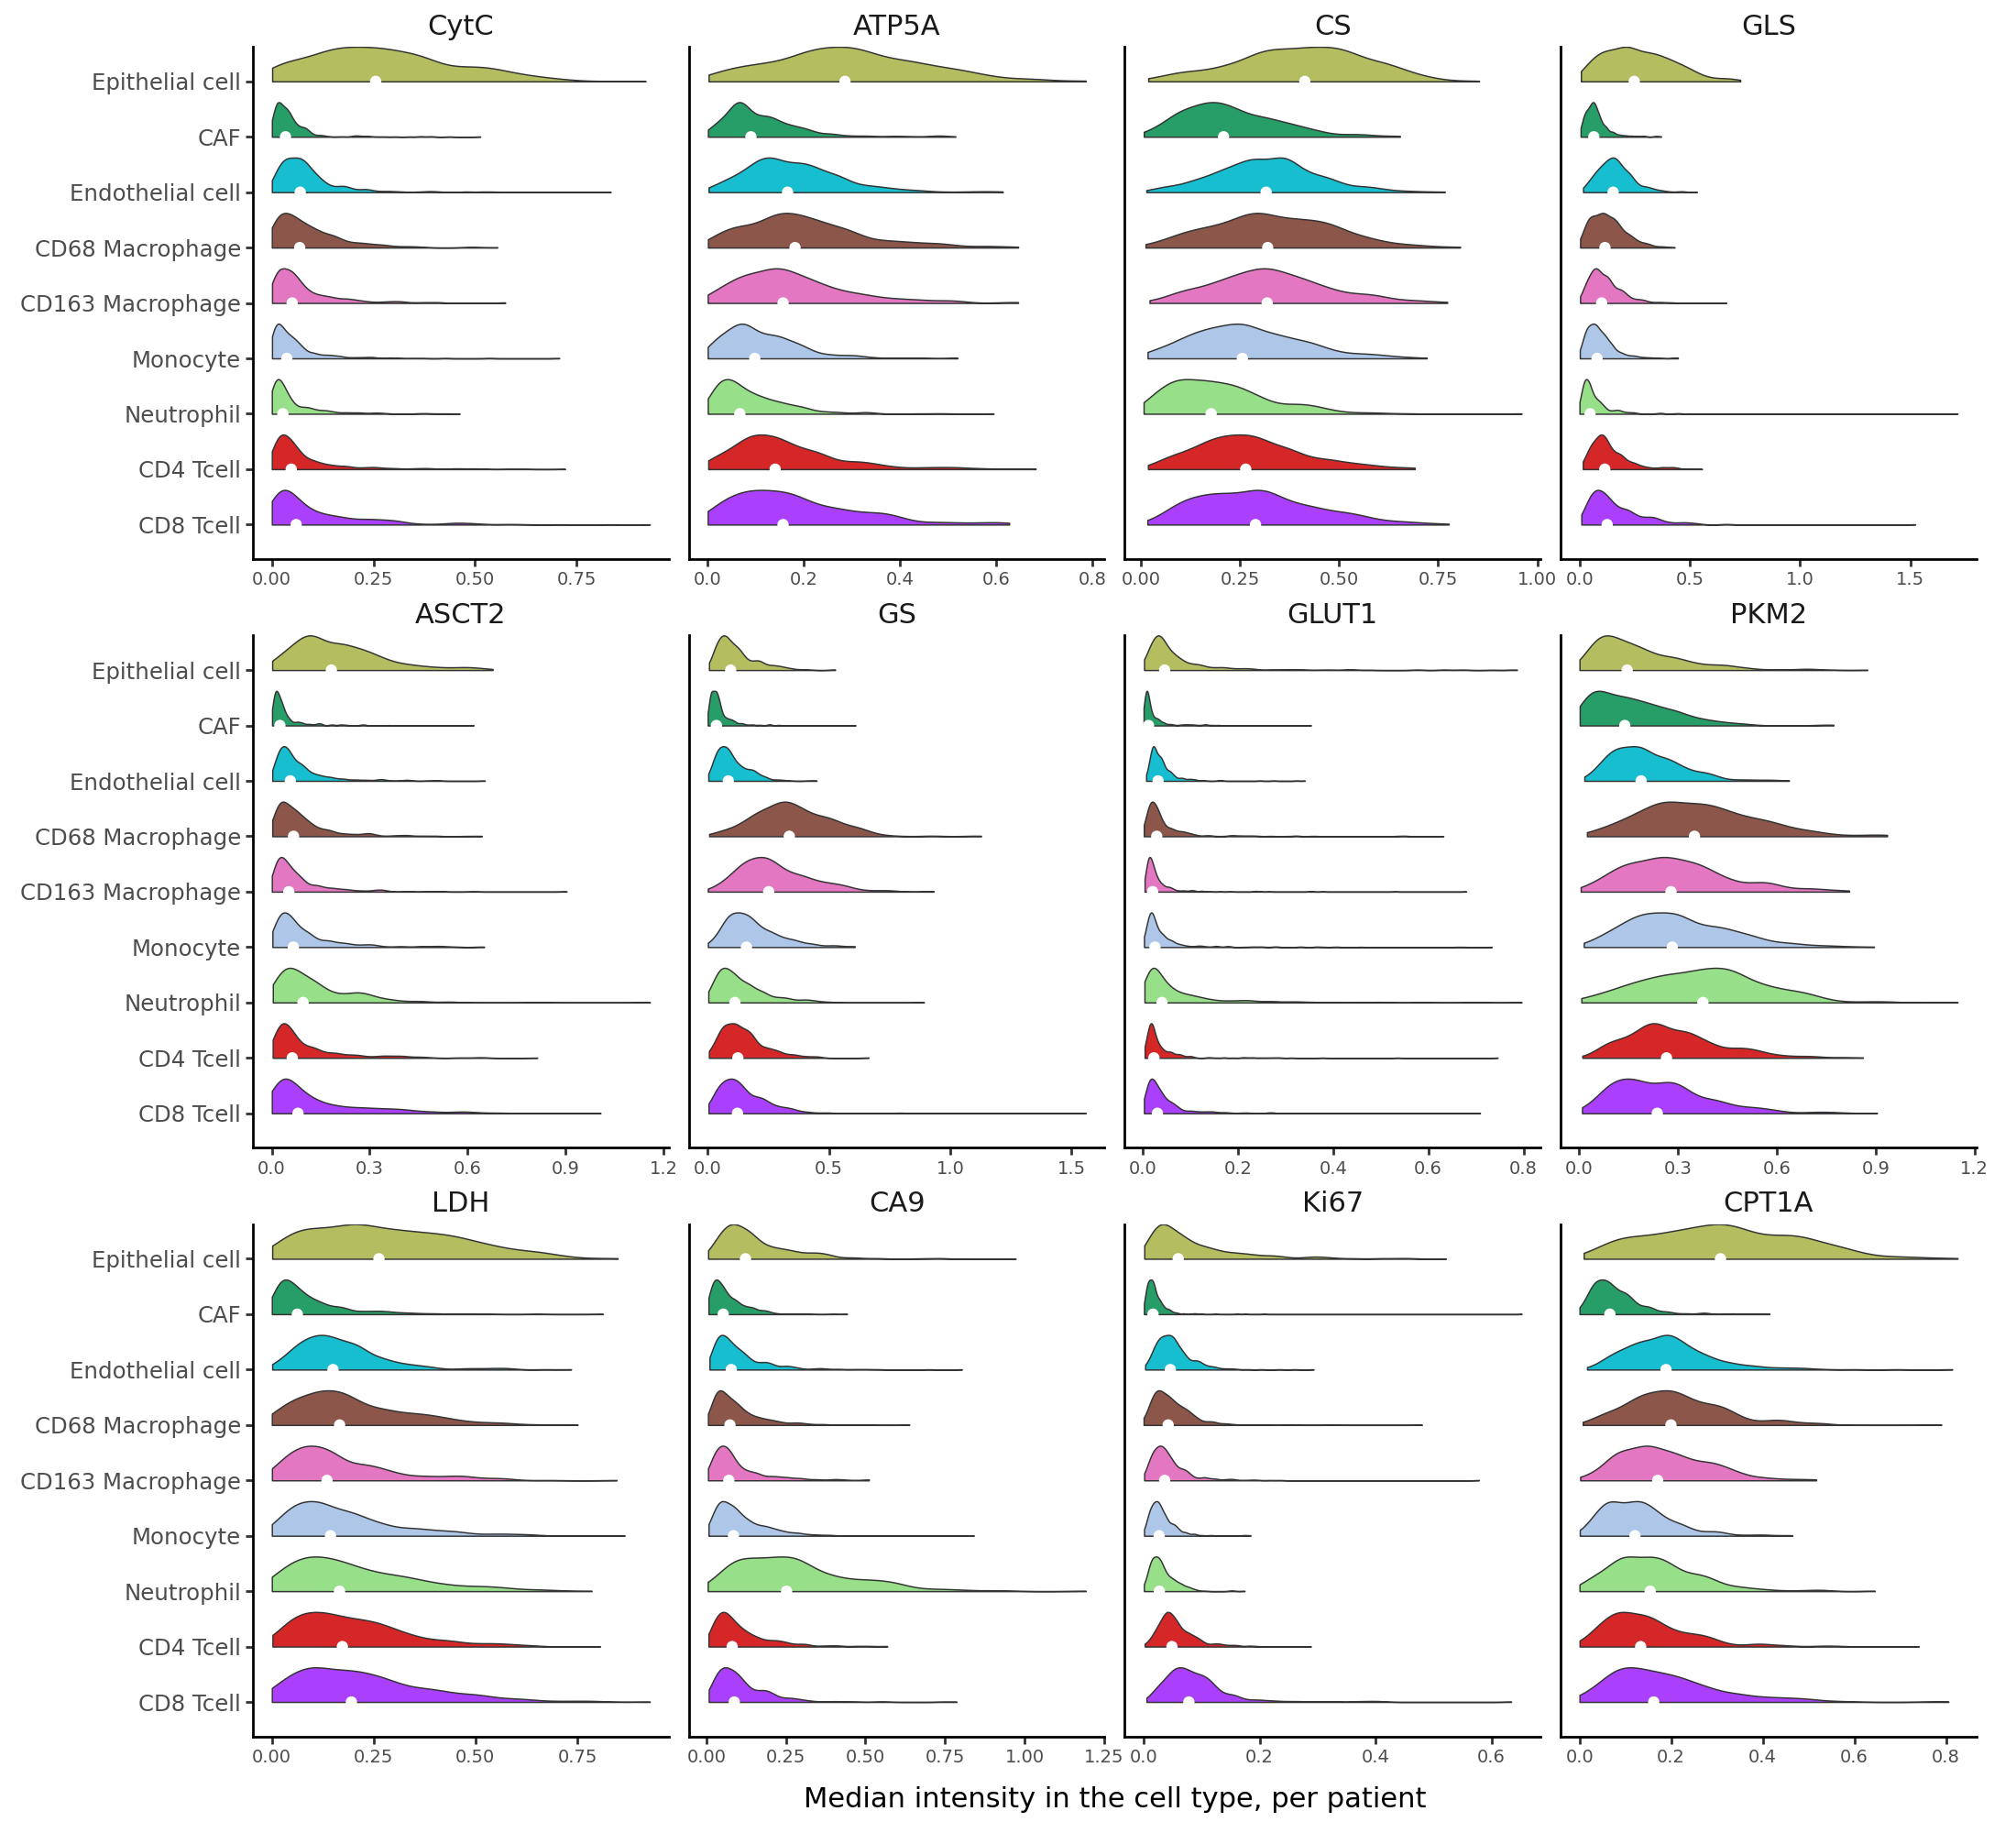

In [7]:
type_colors = dict(zip(ad.read_h5ad(data_dir + "adata_consensus_cell_types.h5ad", backed="r").obs["annotation_consensus"].cat.categories,
                       default_20))
qc_types = ["Cancer_cell", "CAF", "Endothelial_cell", "CD68_Macrophage", "CD163_Macrophage", "Monocyte",
            "Neutrophil", "CD4_Tcell", "CD8_Tcell"]
type_names = {t: "Epithelial cell" if t == epithelial_label else t.replace("_", " ") for t in qc_types}

type_medians = (cells[cells.cell_type.isin(qc_types)]
                .groupby(["fov", "cell_type"])[marker_columns].median().reset_index()
                .melt(id_vars=["fov", "cell_type"], var_name="marker", value_name="median"))
type_medians["marker"] = pd.Categorical(type_medians.marker, categories=marker_columns)
type_medians["cell_type"] = pd.Categorical(type_medians.cell_type.map(type_names),
                                           categories=[type_names[t] for t in qc_types][::-1])

gp = (ggplot(type_medians, aes(x="cell_type", y="median"))
      + half_violins("cell_type")
      + coord_flip()
      + facet_wrap("~marker", scales="free_x", ncol=4)
      + scale_fill_manual(values={type_names[t]: type_colors[t] for t in qc_types})
      + labs(x="", y="Median intensity in the cell type, per patient")
      + theme_classic()
      + theme(figure_size=(11, 10), legend_position="none", axis_text_x=element_text(size=7),
              strip_background=element_blank(), strip_text=element_text(size=11)))
gp.save(figure_dir + "marker_medians_per_cell_type.pdf", verbose=False)
gp

Markers that are clearly higher in epithelial cells than in the other cell types give the most specific epithelial readouts. Markers that are about as high in immune and stromal cells can make a MuVI factor load on them in every cell type, through a signal shared by all cells of a core. Section 5 checks for this pattern in the loadings.

### Agreement between the markers of a process
Agreement is measured at two levels:
- between the epithelial cells of one patient, as the median over patients of the Spearman correlation across cells,
- between patients, as the Spearman correlation of the median per patient.

Composites are computed per patient, so the rule of section 1 uses the agreement between patients.

In [8]:
epithelial_cells = cells[cells.epithelial]
epithelial_medians = epithelial_cells.groupby("fov")[marker_columns + ["area"]].median().loc[patients]

agreement = []
for process, process_markers in markers.items():
    for i, m1 in enumerate(process_markers):
        for m2 in process_markers[i + 1:]:
            within = epithelial_cells.groupby("fov").apply(lambda d: spearmanr(d[m1], d[m2])[0], include_groups=False)
            agreement.append({"process": process, "pair": f"{m1} - {m2}",
                              "within patients, median rho": within.median(),
                              "between patients, rho": spearmanr(epithelial_medians[m1], epithelial_medians[m2])[0]})
agreement = pd.DataFrame(agreement)

use_composite = {}
for process, process_markers in composite_markers.items():
    pairs = [f"{m1} - {m2}" for i, m1 in enumerate(process_markers) for m2 in process_markers[i + 1:]]
    use_composite[process] = bool((agreement.set_index("pair").loc[pairs, "between patients, rho"] >= composite_min_rho).all())
print("Composite used:", use_composite)
agreement.round(2)

Composite used: {'A': True, 'C': False, 'D': False}


,process,pair,"within patients, median rho","between patients, rho"
0,A,CytC - ATP5A,0.80,0.66
1,A,CytC - CS,0.77,0.70
2,A,ATP5A - CS,0.91,0.80
3,C,GLS - ASCT2,0.31,0.49
4,C,GLS - GS,0.26,0.46
5,C,ASCT2 - GS,0.53,0.63
6,D,GLUT1 - PKM2,0.51,0.49
7,D,GLUT1 - LDH,0.32,0.40
8,D,PKM2 - LDH,0.57,0.49


Processes whose markers do not all agree keep one readout per marker. Averaging markers that vary independently would blur two different signals into one.

### CA9 in myeloid cells
A segmented cell can pick up signal from a neighbour. If myeloid CA9 came from such spillover, it would be high only in myeloid cells that touch a CA9-high epithelial cell and fall to background one cell further. A gradual decline over tens of µm would instead fit a hypoxic region, where all cells are exposed.

The plot shows CA9 of myeloid cells against the distance to the nearest CA9-high epithelial cell. Each half violin gives the medians per patient in one distance bin. The dashed line marks the CA9-high cutoff of epithelial cells.

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals


CA9-high cutoff of epithelial cells: 0.215
distance_bin
< 10     0.224
10-20    0.151
20-40    0.108
40-80    0.081
> 80     0.064


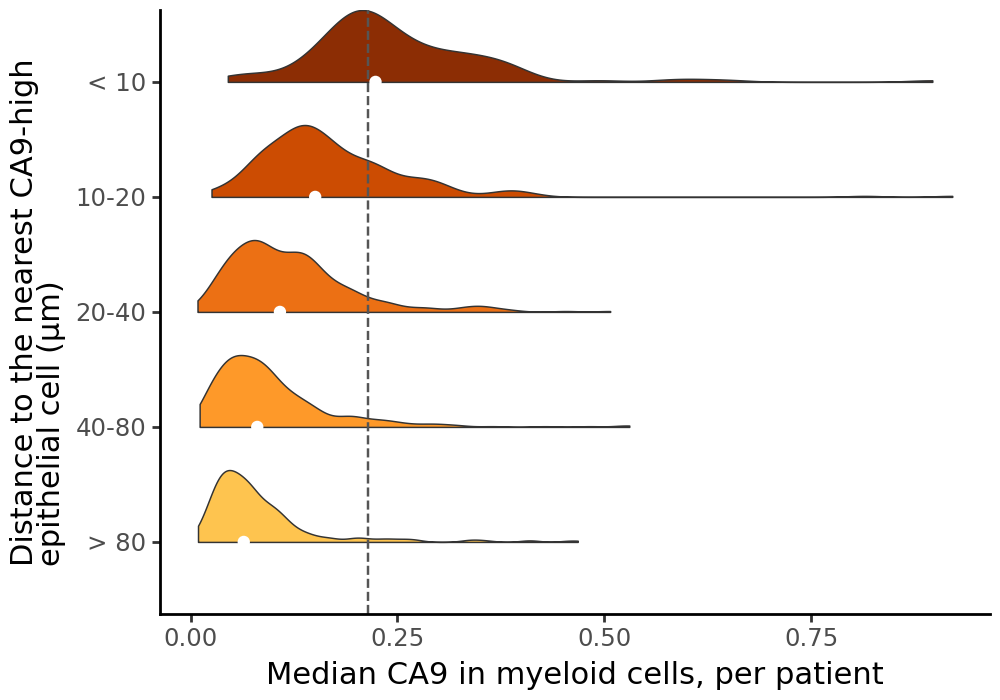

In [9]:
ca9_cutoff = epithelial_cells.CA9.quantile(ca9_quantile)
cells["ca9_high"] = cells.epithelial & (cells.CA9 > ca9_cutoff)

myeloid_distances = []
for fov, fov_cells in cells.groupby("fov"):
    reference = fov_cells.loc[fov_cells.ca9_high, ["x", "y"]].values
    if len(reference) == 0:
        continue
    m = fov_cells[fov_cells.myeloid].copy()
    m["distance"] = cKDTree(reference).query(m[["x", "y"]].values)[0] * um_per_px
    myeloid_distances.append(m[["fov", "cell_type", "CA9", "GLUT1", "distance"]])
myeloid_distances = pd.concat(myeloid_distances)

bin_labels = ["< 10", "10-20", "20-40", "40-80", "> 80"]
myeloid_distances["distance_bin"] = pd.cut(myeloid_distances.distance, bins=[0, 10, 20, 40, 80, np.inf],
                                           labels=bin_labels, right=False)
spillover = (myeloid_distances.groupby(["fov", "distance_bin"], observed=True)
             .agg(CA9=("CA9", "median"), n=("CA9", "size")).reset_index())
spillover = spillover[spillover.n >= 3]
spillover["distance_bin"] = pd.Categorical(spillover.distance_bin, categories=bin_labels[::-1])

gp = (ggplot(spillover, aes(x="distance_bin", y="CA9"))
      + half_violins("distance_bin")
      + geom_hline(yintercept=ca9_cutoff, linetype="dashed", color="#555555")
      + coord_flip()
      + scale_fill_manual(values=dict(zip(bin_labels, ["#8c2d04", "#cc4c02", "#ec7014", "#fe9929", "#fec44f"])))
      + labs(x="Distance to the nearest CA9-high\nepithelial cell (µm)", y="Median CA9 in myeloid cells, per patient")
      + theme_classic()
      + theme(figure_size=(5, 3.5), legend_position="none"))
gp.save(figure_dir + "myeloid_ca9_by_distance.pdf", verbose=False)
print(f"CA9-high cutoff of epithelial cells: {ca9_cutoff:.3f}")
print(spillover.groupby("distance_bin", observed=True).CA9.median().loc[bin_labels].round(3).to_string())
gp

If myeloid CA9 keeps declining well past the closest bin, it reflects the hypoxic region more than spillover, although the closest bin may still include some spillover. In both cases myeloid CA9 cannot show that a macrophage is itself hypoxic. The readouts of hypoxia therefore use CA9 in epithelial cells, and relate myeloid cells to it by position.

## 4. Readouts per patient
Each process is measured directly from the cells of each patient. These readouts do not depend on MuVI, which serves two purposes: section 5 can check which factors follow each process, and the readouts can describe processes that no factor captures.

| Readout | Cells | Definition |
|---|---|---|
| A, C and D markers | Epithelial cells | Median intensity of the marker |
| Mitochondrial composite | Epithelial cells | Mean of the z-scores across patients of CytC, ATP5A and CS, if they agree. The same rule applies to C and D |
| Epithelial contrast | Epithelial cells against all other annotated cells | Median in epithelial cells minus median in the other cells of the core. It removes the part of the signal that all cells of a core share, such as staining intensity |
| Ki67 and cell area | Epithelial cells | Median Ki67 and median area |
| B1, myeloid availability | All cells | Fraction of all cells that are CD68 macrophages, CD163 macrophages, monocytes, or any of the three |
| B2, hypoxia | Epithelial cells | Fraction of epithelial cells that are CA9-high |
| B3, myeloid localisation | Myeloid cells against all other non-epithelial cells | Fraction of myeloid cells with a CA9-high epithelial cell within the radius, divided by the same fraction in all annotated non-epithelial cells, on a log2 scale |
| B4, myeloid state | Myeloid cells | Median GLUT1 of myeloid cells within the larger radius of a CA9-high epithelial cell, minus that of the farther ones |

B3 compares myeloid cells with the other non-epithelial cells of the same core. This keeps the positions of all cells and the pattern of CA9 fixed, and asks whether myeloid cells sit closer to hypoxic epithelium than fibroblasts, endothelial cells or lymphocytes do. Shuffling the CA9-high status among epithelial cells instead would scatter the CA9-high clusters, which would then touch more cells by chance and bias the readout downwards.

Each readout is stored with a label, the cells it describes, and the effect that higher values are expected to have on 5-FU response.

In [10]:
radius_um = {r: f"{r * um_per_px:.0f} µm" for r in radii_px}
readouts = pd.DataFrame(index=patients)
info = []

def add(key, values, process, label, population, expected, mapped=True):
    '''Store a readout with its description; mapped readouts appear in the factor map of section 5'''
    readouts[key] = values
    info.append({"readout": key, "process": process, "label": label, "population": population,
                 "expected": expected, "mapped": mapped})

zscore = lambda s: (s - s.mean()) / s.std()
other_cells = cells[~cells.epithelial & (cells.cell_type != "Unclear")]
other_medians = other_cells.groupby("fov")[marker_columns].median().loc[patients]

composite_names = {"A": "Mitochondrial", "C": "Glutamine", "D": "Glycolytic"}
for process, process_markers in markers.items():
    for m in process_markers:
        add(f"{process} {m}", epithelial_medians[m], process, f"{m}, epithelial cells", "Epithelial cells",
            "no expectation" if m == "GS" else "↑ resistance")
    if use_composite[process]:
        composite = pd.concat([zscore(epithelial_medians[m]) for m in composite_markers[process]], axis=1).mean(axis=1)
        add(f"{process} composite", composite, process, f"{composite_names[process]} composite, epithelial cells",
            "Epithelial cells", "↑ resistance")

for m in markers["A"]:
    add(f"A {m} contrast", epithelial_medians[m] - other_medians[m], "A", f"{m}, epithelial minus other cells",
        "Epithelial against other cells", "↑ resistance")
if use_composite["A"]:
    add("A composite contrast", pd.concat([zscore(readouts[f"A {m} contrast"]) for m in markers["A"]], axis=1).mean(axis=1),
        "A", "Mitochondrial composite, epithelial minus other cells", "Epithelial against other cells", "↑ resistance")

add("Ki67", epithelial_medians["Ki67"], "Proliferation", "Ki67, epithelial cells", "Epithelial cells", "↑ sensitivity")
add("Area", epithelial_medians["area"], "Size", "Cell area, epithelial cells", "Epithelial cells", "no expectation", mapped=False)

type_fractions = pd.crosstab(cells.fov, cells.cell_type, normalize="index").loc[patients]
for t, name in [("CD68_Macrophage", "CD68 macrophages"), ("CD163_Macrophage", "CD163 macrophages"), ("Monocyte", "Monocytes")]:
    add(f"B1 {name}", type_fractions[t], "B", f"{name}, fraction of all cells", "All cells", "↑ resistance if hypoxic")
add("B1 Myeloid", type_fractions[myeloid_types].sum(axis=1), "B", "Myeloid cells, fraction of all cells", "All cells",
    "↑ resistance if hypoxic")

for quantile in [ca9_quantile] + ca9_quantiles_sensitivity:
    cutoff = epithelial_cells.CA9.quantile(quantile)
    fraction = epithelial_cells.CA9.gt(cutoff).groupby(epithelial_cells.fov).mean().loc[patients]
    main = quantile == ca9_quantile
    add("B2 CA9-high" if main else f"B2 CA9-high, q{int(quantile * 100)}", fraction, "B",
        "CA9-high fraction of epithelial cells" + ("" if main else f", cutoff at q{int(quantile * 100)}"),
        "Epithelial cells", "↑ resistance", mapped=main)

In [11]:
def localisation(fov_cells, radius):
    '''log2 of the fraction of myeloid cells near a CA9-high epithelial cell over that of all non-epithelial cells'''
    non_epithelial = (~fov_cells.epithelial & (fov_cells.cell_type != "Unclear")).values
    myeloid = fov_cells.myeloid.values
    high = fov_cells.ca9_high.values
    if myeloid.sum() < min_myeloid_cells or high.sum() == 0:
        return np.nan
    xy = fov_cells[["x", "y"]].values
    near = cKDTree(xy[high]).query(xy, distance_upper_bound=radius)[0] <= radius
    return np.log2((near[myeloid].mean() + 0.01) / (near[non_epithelial].mean() + 0.01))

b3 = {r: {} for r in radii_px}
b4 = {}
for fov, fov_cells in cells.groupby("fov"):
    for r in radii_px:
        b3[r][fov] = localisation(fov_cells, r)
    m = myeloid_distances[myeloid_distances.fov == fov]
    near = m.distance < max(radii_px) * um_per_px
    if near.sum() >= min_cells_near_far and (~near).sum() >= min_cells_near_far:
        b4[fov] = m.GLUT1[near].median() - m.GLUT1[~near].median()

for r in radii_px:
    add(f"B3 {radius_um[r]}", pd.Series(b3[r]), "B", f"Myeloid cells near CA9-high epithelial cells, {radius_um[r]}",
        "Myeloid against other non-epithelial cells", "↑ resistance")
add("B4", pd.Series(b4), "B", "GLUT1 in myeloid cells, near minus far from CA9-high epithelial cells", "Myeloid cells",
    "no expectation")

readout_info = pd.DataFrame(info).set_index("readout")
readout_info.assign(patients=readouts.notna().sum())

,process,label,population,expected,mapped,patients
readout,,,,,,
A CytC,A,"CytC, epithelial cells",Epithelial cells,↑ resistance,True,418
A ATP5A,A,"ATP5A, epithelial cells",Epithelial cells,↑ resistance,True,418
A CS,A,"CS, epithelial cells",Epithelial cells,↑ resistance,True,418
A composite,A,"Mitochondrial composite, epithelial cells",Epithelial cells,↑ resistance,True,418
C GLS,C,"GLS, epithelial cells",Epithelial cells,↑ resistance,True,418
C ASCT2,C,"ASCT2, epithelial cells",Epithelial cells,↑ resistance,True,418
C GS,C,"GS, epithelial cells",Epithelial cells,no expectation,True,418
D GLUT1,D,"GLUT1, epithelial cells",Epithelial cells,↑ resistance,True,418
D PKM2,D,"PKM2, epithelial cells",Epithelial cells,↑ resistance,True,418


### Do the mitochondrial readouts reflect epithelial cells, proliferation or cell size?
Three alternatives could explain the mitochondrial readouts besides epithelial machinery:
- the staining intensity of the core, which all its cells share and which the epithelial contrast removes,
- proliferation, since dividing cells build more mitochondria,
- cell size, since larger cells hold more of every protein.

The table gives the Spearman correlations across patients between the mitochondrial readouts, their contrasts, Ki67 and cell area.

In [12]:
a_keys = [k for k in readouts if k.startswith("A ") and k.split(" ")[1] in markers["A"] + ["composite"]] + ["Ki67", "Area"]
pd.DataFrame(spearmanr(readouts[a_keys].values)[0], index=a_keys, columns=a_keys).round(2)

,A CytC,A ATP5A,A CS,A composite,A CytC contrast,A ATP5A contrast,A CS contrast,A composite contrast,Ki67,Area
A CytC,1.00,0.66,0.70,0.87,0.90,0.51,0.40,0.70,0.28,0.08
A ATP5A,0.66,1.00,0.80,0.90,0.60,0.83,0.46,0.72,0.29,0.16
A CS,0.70,0.80,1.00,0.91,0.64,0.61,0.57,0.70,0.49,0.22
A composite,0.87,0.90,0.91,1.00,0.79,0.71,0.50,0.77,0.38,0.16
A CytC contrast,0.90,0.60,0.64,0.79,1.00,0.59,0.58,0.84,0.21,0.10
A ATP5A contrast,0.51,0.83,0.61,0.71,0.59,1.00,0.66,0.87,0.18,0.11
A CS contrast,0.40,0.46,0.57,0.50,0.58,0.66,1.00,0.86,0.12,0.20
A composite contrast,0.70,0.72,0.70,0.77,0.84,0.87,0.86,1.00,0.19,0.15
Ki67,0.28,0.29,0.49,0.38,0.21,0.18,0.12,0.19,1.00,0.14
Area,0.08,0.16,0.22,0.16,0.10,0.11,0.20,0.15,0.14,1.00


A high correlation between a readout and its contrast means that most of its variation between patients is specific to epithelial cells. Correlations with Ki67 or area well below 1 mean that proliferation and size explain only part of it.

### Does the CA9 cutoff matter?
B2 depends on the cutoff that makes an epithelial cell CA9-high. If the ranking of patients barely changes with the cutoff, the readout does not hinge on that choice.

In [13]:
b2_keys = [k for k in readouts if k.startswith("B2")]
pd.DataFrame(spearmanr(readouts[b2_keys].values)[0], index=b2_keys, columns=b2_keys).round(2)

,B2 CA9-high,"B2 CA9-high, q50","B2 CA9-high, q90"
B2 CA9-high,1.00,0.95,0.90
"B2 CA9-high, q50",0.95,1.00,0.84
"B2 CA9-high, q90",0.90,0.84,1.00


### Are myeloid cells near hypoxic epithelium?
The DPD mechanism needs myeloid cells in hypoxic tissue. B3 measures this per patient. A value of 0 means that myeloid cells are as close to CA9-high epithelial cells as other non-epithelial cells are. A Wilcoxon signed-rank test across patients asks whether the median differs from 0. The same applies to B4, the difference in myeloid GLUT1 near and far from CA9-high epithelial cells.

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals


,patients,median,lower quartile,upper quartile,patients above 0,p
readout,,,,,,
"Myeloid cells near CA9-high epithelial cells, 16 µm",367,-0.0671,-0.5111,0.2403,139,0.0004
"Myeloid cells near CA9-high epithelial cells, 47 µm",367,0.0000,-0.2008,0.2300,179,0.6939
"GLUT1 in myeloid cells, near minus far from CA9-high epithelial cells",260,0.0065,0.0005,0.0220,201,0.0000


/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals


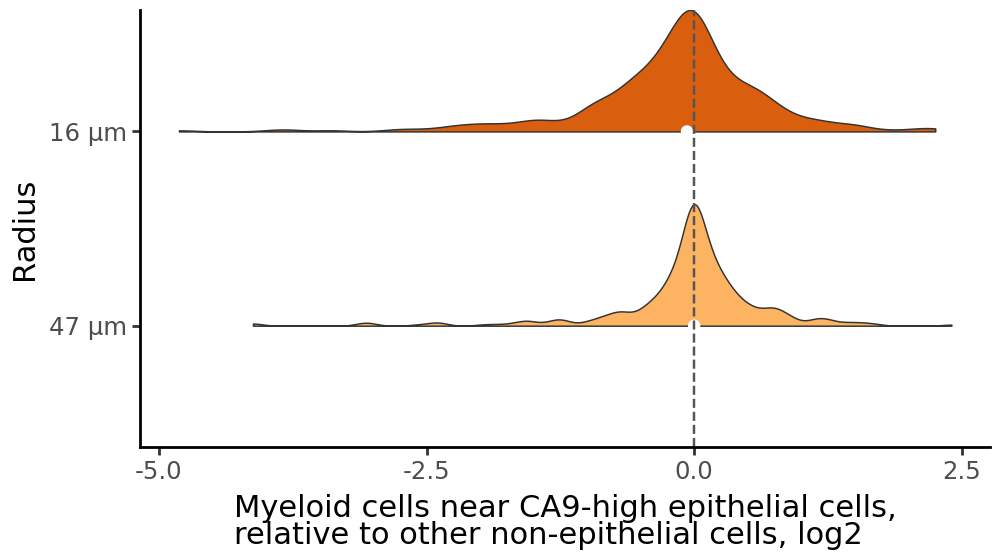

In [14]:
spatial_keys = [k for k in readouts if k.startswith("B3") or k == "B4"]
spatial_tests = pd.DataFrame([
    {"readout": readout_info.loc[k, "label"], "patients": readouts[k].notna().sum(), "median": readouts[k].median(),
     "lower quartile": readouts[k].quantile(0.25), "upper quartile": readouts[k].quantile(0.75),
     "patients above 0": (readouts[k] > 0).sum(), "p": wilcoxon(readouts[k].dropna()).pvalue}
    for k in spatial_keys
]).set_index("readout")

b3_df = readouts[[f"B3 {radius_um[r]}" for r in radii_px]].melt(var_name="radius", value_name="log2 ratio").dropna()
b3_df["radius"] = pd.Categorical(b3_df.radius.str.replace("B3 ", ""), categories=[radius_um[r] for r in radii_px][::-1])
gp = (ggplot(b3_df, aes(x="radius", y="log2 ratio"))
      + half_violins("radius")
      + geom_hline(yintercept=0, linetype="dashed", color="#555555")
      + coord_flip()
      + scale_fill_manual(values=["#fdb462", "#d95f0e"])
      + labs(x="Radius", y="Myeloid cells near CA9-high epithelial cells,\nrelative to other non-epithelial cells, log2")
      + theme_classic()
      + theme(figure_size=(5, 2.8), legend_position="none"))
gp.save(figure_dir + "myeloid_localisation.pdf", verbose=False)
display(spatial_tests.round(4))
gp

A median near 0 means that, in the typical patient, myeloid cells show no specific attraction to hypoxic epithelium. Patients far above 0 have myeloid cells gathered near hypoxic epithelium, the configuration in which the DPD mechanism would be most plausible. Patients with too few myeloid cells or no CA9-high epithelial cell have no value. GLUT1 can spill over from hypoxic epithelial cells, which express it too, so a small shift in B4 does not show a distinct myeloid state.

## 5. Processes in the factors
Two complementary views show how the factors relate to the processes:
- The loadings show which features of which cell types each factor weighs. This tells whether a factor carries a marker in epithelial cells specifically or in all cell types of a core.
- The correlations between factor scores and readouts show which factors follow each process across patients. These include readouts that MuVI never saw, such as the spatial ones.

### Loadings of the process markers in each cell type
Loadings of the retained MuVI model, as exported by `sampling/FactorActivity.ipynb`. For markers, the feature is the median of the marker in the cell type of the row. For the proportion, it is the fraction of all cells of the core that belong to the cell type.

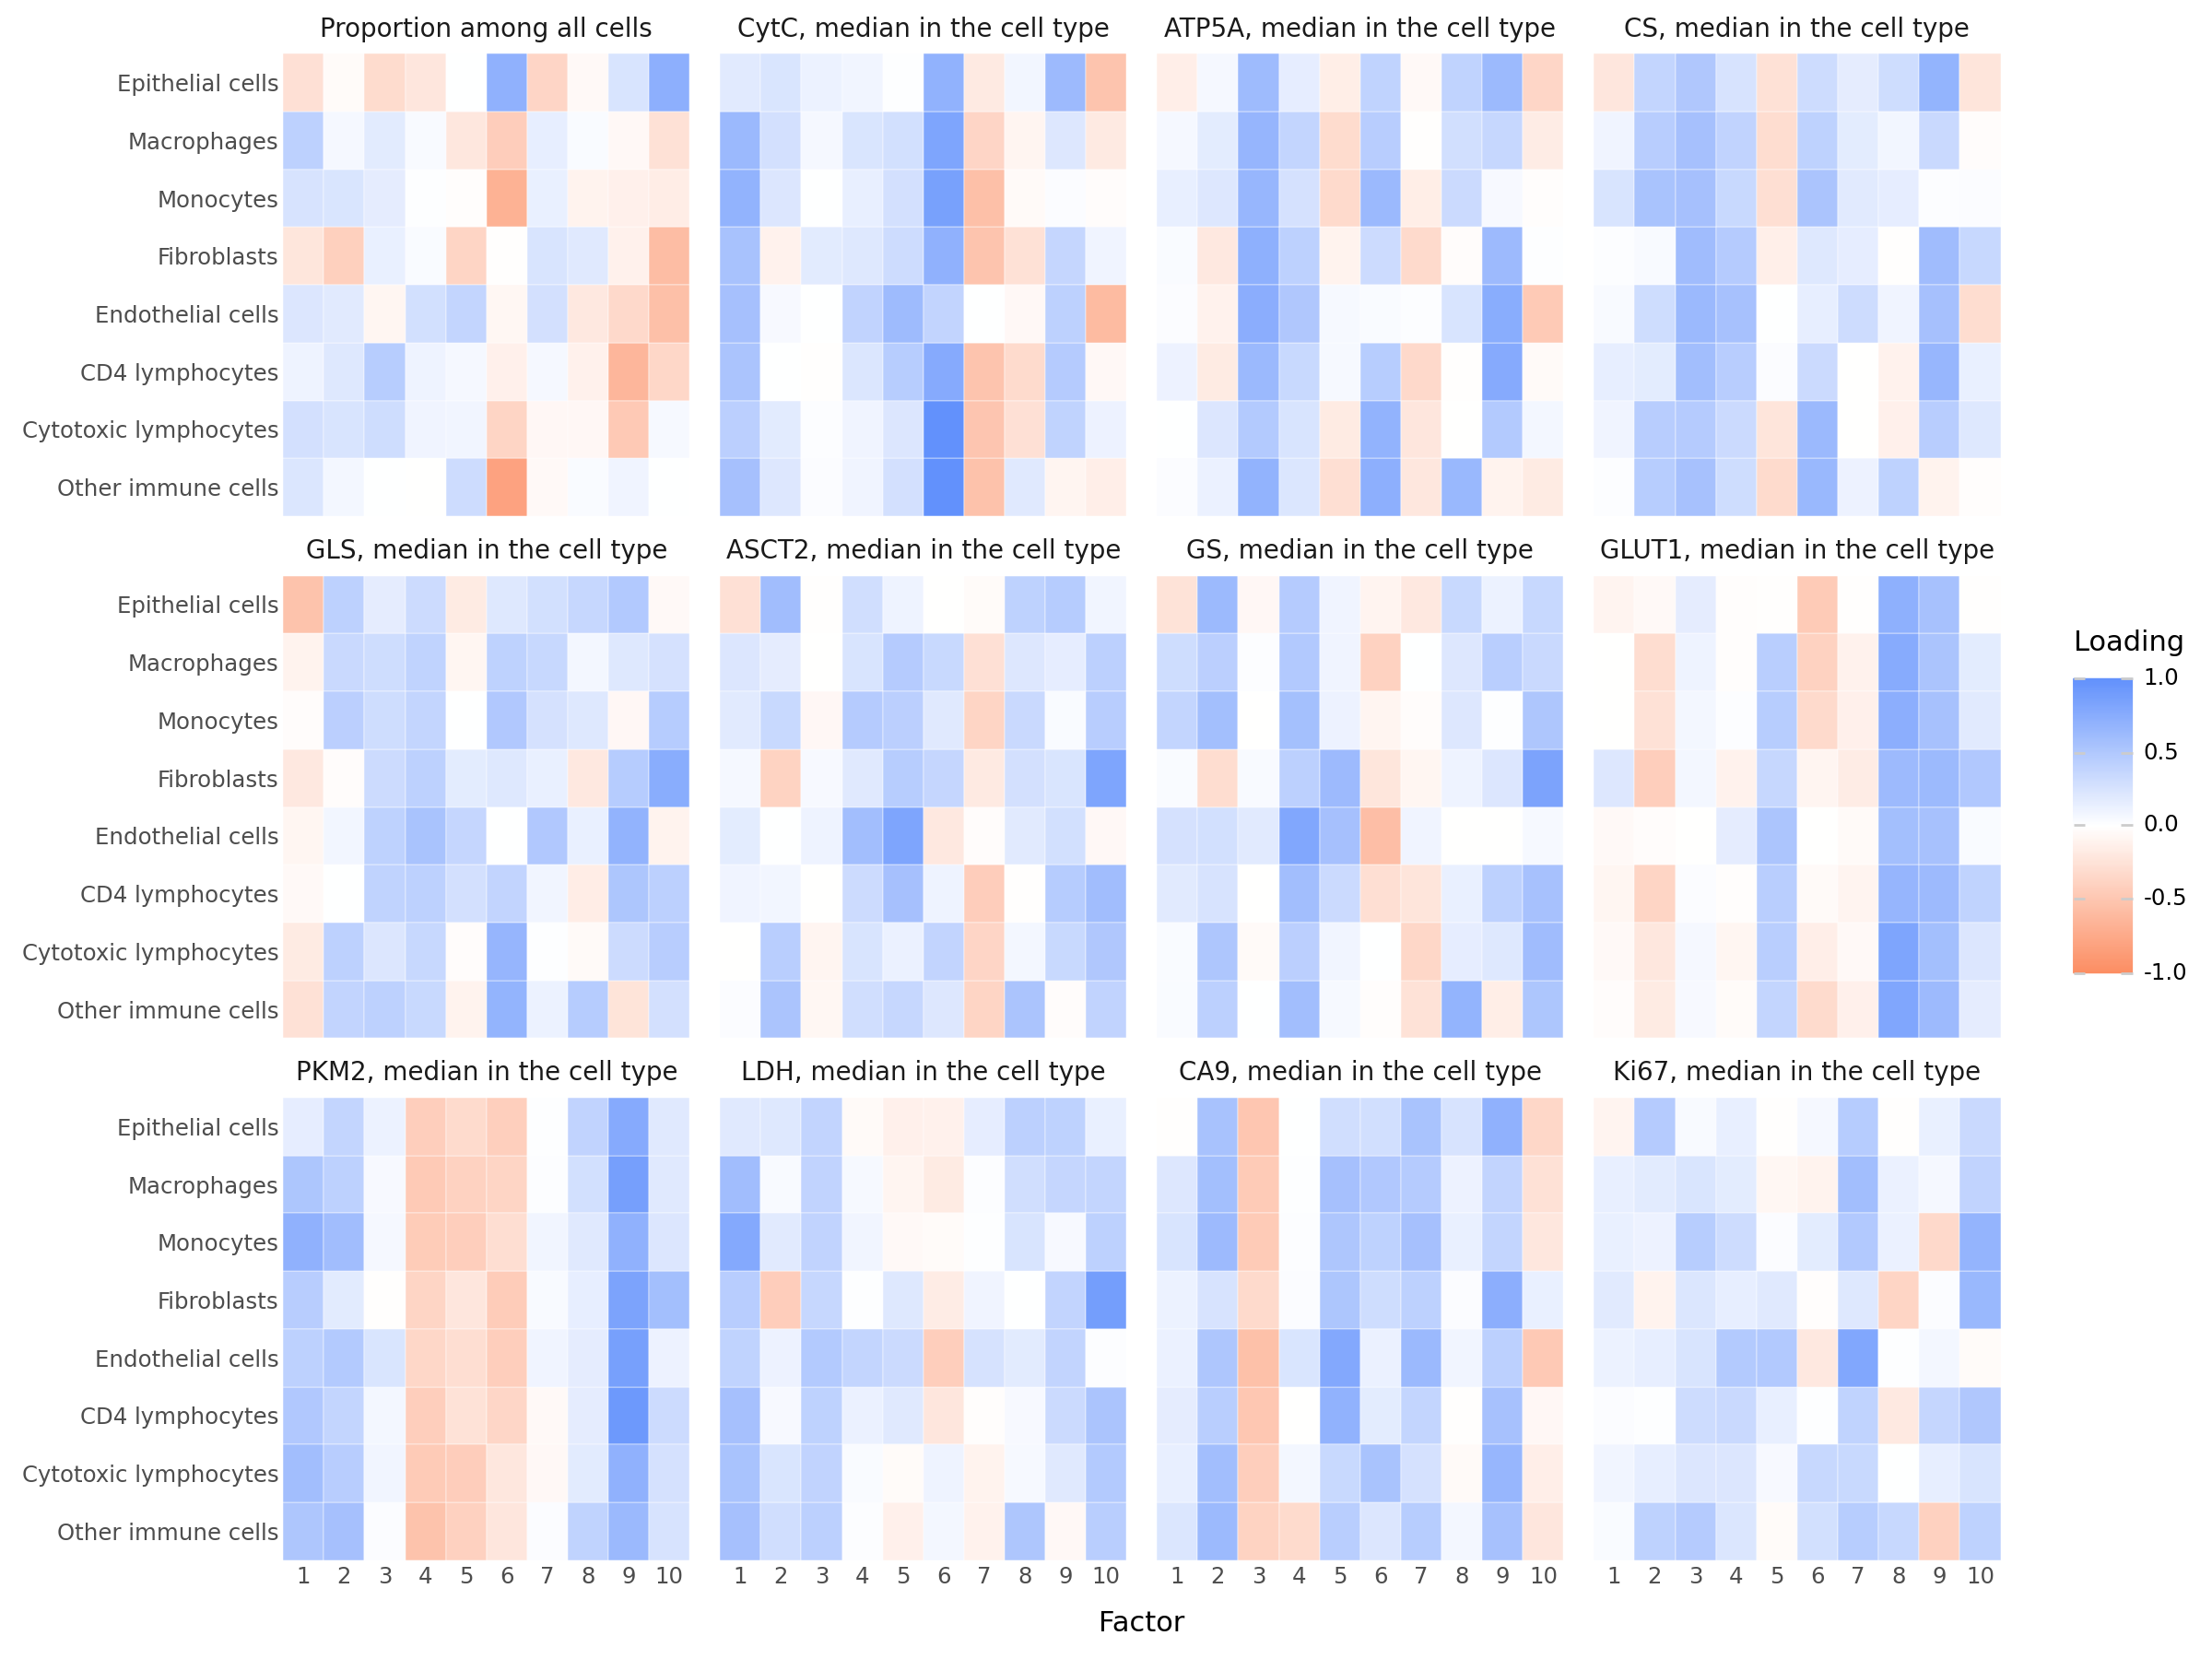

In [15]:
loadings = pd.read_csv(data_dir + "sampling/muvi_reference_loadings.csv")
map_markers = ["proportion", "CytC", "ATP5A", "CS", "GLS", "ASCT2", "GS", "GLUT1", "PKM2", "LDH", "CA9", "Ki67"]
facet_names = {"proportion": "Proportion among all cells", **{m: f"{m}, median in the cell type" for m in map_markers[1:]}}
view_order = ["Epithelial_cell", "Macrophage", "Monocyte", "Fibroblast", "Endothelial_cell",
              "CD4_lymphocyte", "Cytotoxic_lymphocyte", "Other_immune_cell"]
view_labels = {"Epithelial_cell": "Epithelial cells", "Macrophage": "Macrophages", "Monocyte": "Monocytes",
               "Fibroblast": "Fibroblasts", "Endothelial_cell": "Endothelial cells", "CD4_lymphocyte": "CD4 lymphocytes",
               "Cytotoxic_lymphocyte": "Cytotoxic lymphocytes", "Other_immune_cell": "Other immune cells"}

marker_loadings = (loadings[loadings.feature.isin(map_markers)]
                   .melt(id_vars=["view", "feature"], value_vars=factor_order, var_name="factor", value_name="loading"))
marker_loadings["feature"] = pd.Categorical(marker_loadings.feature.map(facet_names), categories=[facet_names[m] for m in map_markers])
marker_loadings["view"] = pd.Categorical(marker_loadings.view.map(view_labels), categories=[view_labels[v] for v in view_order][::-1])
marker_loadings["factor"] = pd.Categorical(marker_loadings.factor.str.replace("Factor ", ""), categories=[str(i) for i in range(1, 11)])

gp = (ggplot(marker_loadings, aes(x="factor", y="view", fill="loading"))
      + geom_tile(color="white")
      + facet_wrap("~feature", ncol=4)
      + scale_fill_correlation("Loading")
      + labs(x="Factor", y="")
      + theme_classic()
      + theme(figure_size=(12, 9), axis_line=element_blank(), axis_ticks=element_blank(),
              strip_background=element_blank(), strip_text=element_text(size=10)))
gp.save(figure_dir + "process_marker_loadings.pdf", verbose=False)
gp

To compare epithelial cells with the rest, the table subtracts from each epithelial loading the mean loading of the same feature in the other cell types. Values near 0 mean that the factor weighs the marker in all cell types alike.

In [16]:
wide = loadings[loadings.feature.isin(map_markers)].set_index(["view", "feature"])[factor_order]
epithelial_loadings = wide.xs("Epithelial_cell", level="view")
other_mean = wide.drop("Epithelial_cell", level="view").groupby("feature").mean()
(epithelial_loadings - other_mean.loc[epithelial_loadings.index]).loc[map_markers].round(2)

,Factor 1,Factor 2,Factor 3,Factor 4,Factor 5,Factor 6,Factor 7,Factor 8,Factor 9,Factor 10
feature,,,,,,,,,,
proportion,-0.46,-0.12,-0.48,-0.30,-0.03,1.07,-0.48,-0.02,0.49,0.98
CytC,-0.38,0.12,0.08,-0.12,-0.34,-0.10,0.24,0.20,0.36,-0.40
ATP5A,-0.20,0.03,-0.04,-0.18,0.00,-0.07,0.12,0.19,0.21,-0.24
CS,-0.32,0.03,-0.06,-0.15,-0.09,-0.10,0.03,0.24,0.32,-0.28
GLS,-0.40,0.18,-0.18,-0.09,-0.26,-0.20,0.08,0.30,0.22,-0.41
ASCT2,-0.39,0.43,0.00,-0.04,-0.35,-0.21,0.25,0.17,0.25,-0.36
GS,-0.43,0.32,-0.10,-0.09,-0.17,0.13,-0.08,0.13,-0.05,-0.14
GLUT1,-0.10,0.20,0.11,-0.01,-0.45,-0.27,0.09,0.00,-0.02,-0.25
PKM2,-0.37,-0.06,0.05,0.00,0.03,-0.09,-0.01,0.18,-0.02,-0.08


When a metabolic marker loads with the same sign and a similar size in every cell type, the factor describes the core as a whole. Either all its cells share a metabolic state, or the staining intensity differs between cores. The loadings cannot tell these apart, which is why the epithelial contrast of section 4 matters for A. Large values for the proportion mean that the factor tracks how much of the core is epithelium.

### Factor scores against the readouts
Spearman correlation between each factor score and each readout, across patients. Readouts fall into three groups by how they relate to the MuVI input:
- **MuVI input.** The readout is one of the features MuVI was fit on, so a correlation is partly built in. It shows which factor carries the process, not independent evidence.
- **Same channels, new summary.** The readout uses the same measurements but summarises them differently, such as a composite, a contrast or a fraction of CA9-high cells.
- **Spatial, not a MuVI input.** The readout uses cell positions in a way that no MuVI feature does.

Dots mark correlations that pass an FDR of 5% across the whole matrix, with the Benjamini-Hochberg correction.

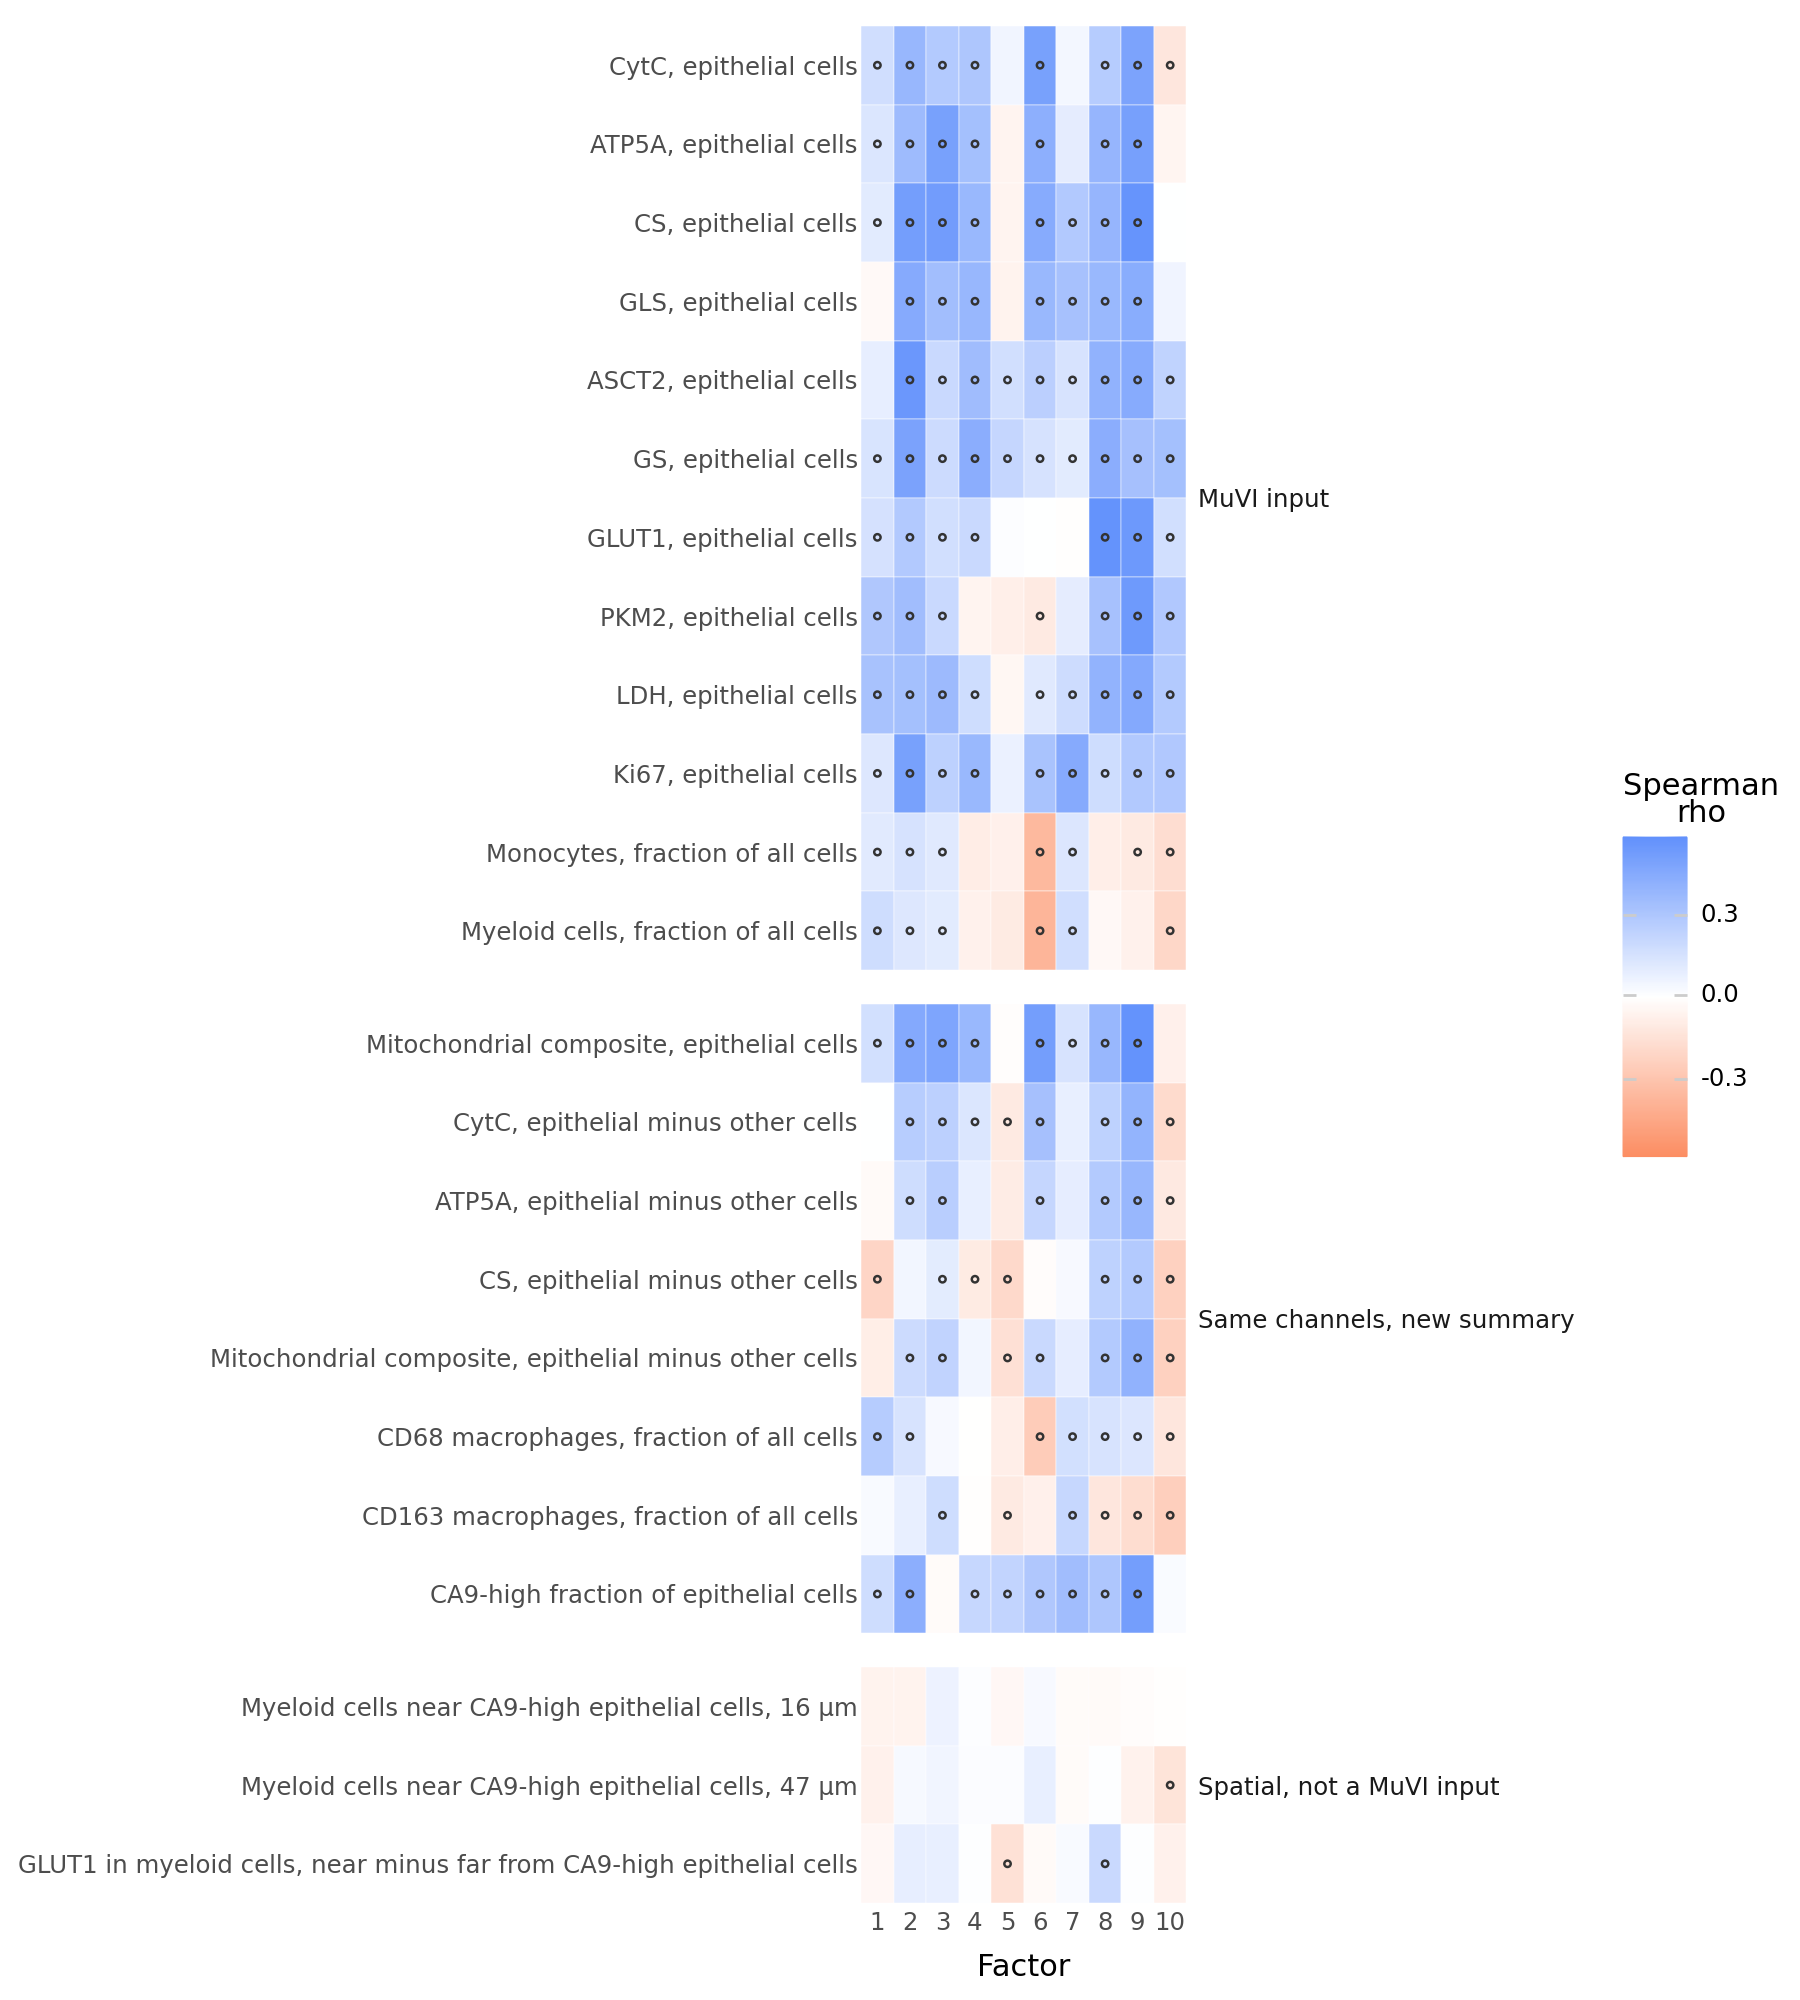

In [17]:
muvi_inputs = [f"{p} {m}" for p, ms in markers.items() for m in ms] + ["Ki67", "B1 Monocytes", "B1 Myeloid"]
def evidence(key):
    if key.startswith("B3") or key == "B4":
        return "Spatial, not a MuVI input"
    return "MuVI input" if key in muvi_inputs else "Same channels, new summary"
readout_info["evidence"] = [evidence(k) for k in readout_info.index]
map_keys = list(readout_info.index[readout_info.mapped])

correlations = {(k, f): spearmanr(readouts[k], scores[f], nan_policy="omit") for k in map_keys for f in factor_order}
rho = pd.DataFrame({f: [correlations[(k, f)][0] for k in map_keys] for f in factor_order}, index=map_keys)
p = pd.DataFrame({f: [correlations[(k, f)][1] for k in map_keys] for f in factor_order}, index=map_keys)
q = pd.DataFrame(multipletests(p.values.ravel(), method="fdr_bh")[1].reshape(p.shape), index=p.index, columns=p.columns)

map_df = rho.stack().rename("rho").to_frame().join(q.stack().rename("q")).rename_axis(["readout", "factor"]).reset_index()
evidence_order = ["MuVI input", "Same channels, new summary", "Spatial, not a MuVI input"]
map_df["evidence"] = pd.Categorical(map_df.readout.map(readout_info.evidence), categories=evidence_order)
label_order = [readout_info.loc[k, "label"] for e in evidence_order for k in map_keys if readout_info.loc[k, "evidence"] == e]
map_df["label"] = pd.Categorical(map_df.readout.map(readout_info.label), categories=label_order[::-1])
map_df["factor_label"] = pd.Categorical(map_df.factor.str.replace("Factor ", ""), categories=[str(i) for i in range(1, 11)])

gp = (ggplot(map_df, aes(x="factor_label", y="label", fill="rho"))
      + geom_tile(color="white")
      + geom_point(data=map_df[map_df.q < fdr], size=0.8, color="#333333")
      + facet_grid("evidence~.", scales="free_y", space="free_y")
      + scale_fill_correlation("Spearman\nrho", limits=(-0.6, 0.6))
      + labs(x="Factor", y="")
      + theme_classic()
      + theme(figure_size=(9, 10), axis_line=element_blank(), axis_ticks=element_blank(),
              strip_background=element_blank(), strip_text_y=element_text(angle=0, ha="left")))
gp.save(figure_dir + "factor_readout_correlations.pdf", verbose=False)
gp

For each readout, the factor that follows it most closely, with a 95% bootstrap interval over patients.

In [18]:
rng = np.random.default_rng(seed)
best = []
for k in map_keys:
    f = rho.loc[k].abs().idxmax()
    d = pd.concat([readouts[k], scores[f]], axis=1).dropna().values
    boot = []
    for _ in range(n_bootstrap):
        ranks = rankdata(d[rng.integers(0, len(d), len(d))], axis=0)
        boot.append(np.corrcoef(ranks.T)[0, 1])
    best.append({"readout": readout_info.loc[k, "label"], "evidence": readout_info.loc[k, "evidence"], "factor": f,
                 "rho": rho.loc[k, f], "2.5%": np.quantile(boot, 0.025), "97.5%": np.quantile(boot, 0.975), "q": q.loc[k, f]})
pd.DataFrame(best).set_index("readout").round(3)

,evidence,factor,rho,2.5%,97.5%,q
readout,,,,,,
"CytC, epithelial cells",MuVI input,Factor 6,0.514,0.438,0.579,0.000
"ATP5A, epithelial cells",MuVI input,Factor 9,0.520,0.443,0.590,0.000
"CS, epithelial cells",MuVI input,Factor 9,0.585,0.510,0.648,0.000
"Mitochondrial composite, epithelial cells","Same channels, new summary",Factor 9,0.589,0.520,0.650,0.000
"GLS, epithelial cells",MuVI input,Factor 2,0.464,0.378,0.539,0.000
"ASCT2, epithelial cells",MuVI input,Factor 2,0.568,0.498,0.631,0.000
"GS, epithelial cells",MuVI input,Factor 2,0.505,0.424,0.578,0.000
"GLUT1, epithelial cells",MuVI input,Factor 8,0.593,0.529,0.650,0.000
"PKM2, epithelial cells",MuVI input,Factor 9,0.553,0.476,0.622,0.000


How to read the map:
- A factor that follows the mitochondrial composite but much less its epithelial contrast carries mitochondrial machinery shared with the other cells of the core, not specific to epithelial cells.
- A row without strong entries is a process that the factors do not capture. Its readout has to be used directly.

Factors 6 and 9 each follow several processes. Factor 9 rises with the mitochondrial, glutamine and glycolytic markers of epithelial cells and with the CA9-high fraction, and keeps its link with A once the shared signal is removed. Factor 6 rises with the mitochondrial markers and falls with the myeloid fraction. Its loadings also weigh the epithelial proportion of the core. The next section combines the two.

## 6. Factor 6 against Factor 9
Factors 6 and 9 each relate to several processes, in different directions. Placing patients on both at once shows whether the processes combine differently across tumours. Each factor is split at the quantile set in section 1, giving four combinations. The combinations are descriptive categories within this cohort, not clinical cutoffs. The continuous plot comes first, so that the split does not hide a gradient.

### Processes along both factors
Each panel colours the patients by the percentile of one readout across patients. The second line of each panel title gives the effect that higher values are expected to have on 5-FU response, from the experiments listed at the top.

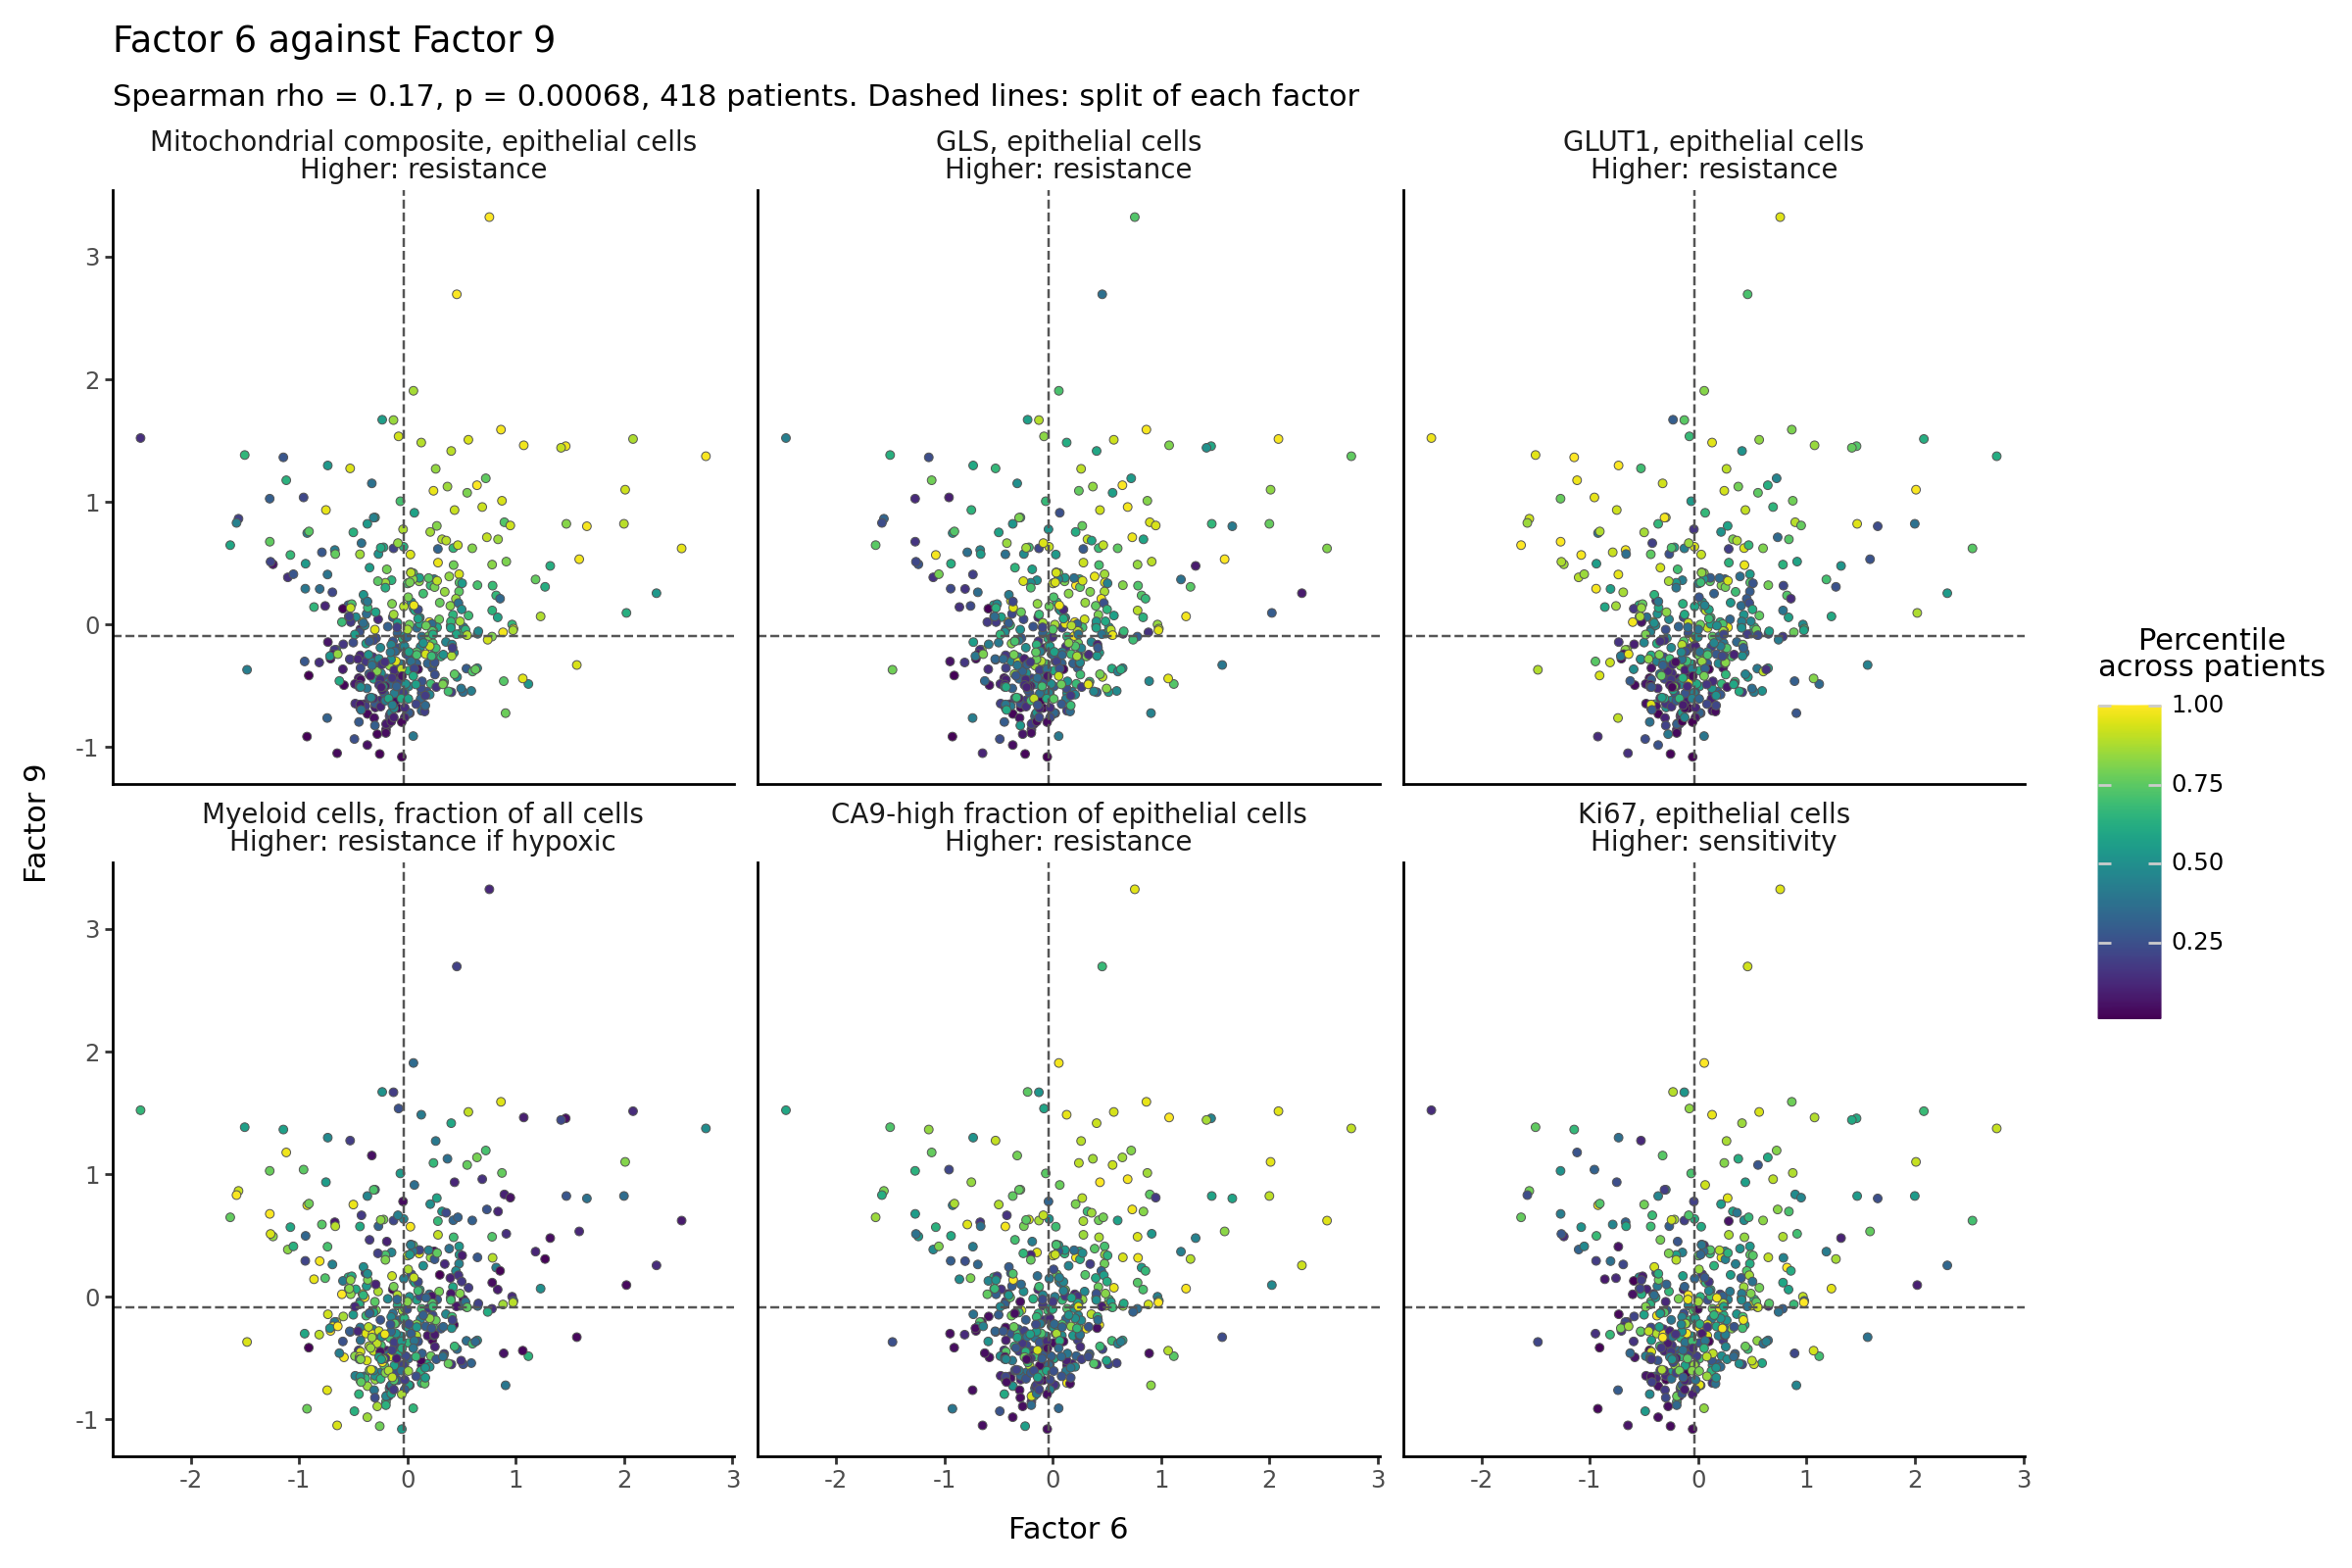

In [19]:
pair = ["Factor 6", "Factor 9"]
pair_rho, pair_p = spearmanr(scores[pair[0]], scores[pair[1]])
cutoffs = scores[pair].quantile(factor_split_quantile)
high = scores[pair] > cutoffs

landscape_keys = ["A composite", "C GLS", "D GLUT1", "B1 Myeloid", "B2 CA9-high", "Ki67"]
panel_names = {k: f"{readout_info.loc[k, 'label']}\nHigher: {readout_info.loc[k, 'expected'].replace('↑ ', '')}" for k in landscape_keys}
landscape = (scores[pair].join(readouts[landscape_keys].rank(pct=True))
             .melt(id_vars=pair, var_name="readout", value_name="percentile"))
landscape["readout"] = pd.Categorical(landscape.readout.map(panel_names), categories=[panel_names[k] for k in landscape_keys])

gp = (ggplot(landscape, aes(x="Factor 6", y="Factor 9", fill="percentile"))
      + geom_point(size=1.6, stroke=0.2, color="#555555")
      + geom_vline(xintercept=cutoffs["Factor 6"], linetype="dashed", color="#555555")
      + geom_hline(yintercept=cutoffs["Factor 9"], linetype="dashed", color="#555555")
      + facet_wrap("~readout", ncol=3)
      + scale_fill_cmap(cmap_name="viridis", name="Percentile\nacross patients")
      + labs(title="Factor 6 against Factor 9",
             subtitle=f"Spearman rho = {pair_rho:.2f}, p = {pair_p:.2g}, {len(scores)} patients. Dashed lines: split of each factor")
      + theme_classic()
      + theme(figure_size=(12, 8), strip_background=element_blank(), strip_text=element_text(size=10)))
gp.save(figure_dir + "factor6_vs_factor9_processes.pdf", verbose=False)
gp

### Process profile of each combination
The heatmap gives, for each readout, the median percentile of the patients of each combination. A value of 0.5 is the median patient of the cohort. The label of each row ends with the effect that higher values are expected to have on 5-FU response. The table tests whether each readout differs across the four combinations, with a Kruskal-Wallis test and the Benjamini-Hochberg FDR across readouts.

,patients
"F6 high, F9 high",126
"F6 high, F9 low",83
"F6 low, F9 high",83
"F6 low, F9 low",126


,p,q (FDR)
"Mitochondrial composite, epithelial cells",9.4e-38,1.5e-36
"Mitochondrial composite, epithelial minus other cells",1.5e-14,3.1e-14
"GLS, epithelial cells",5.4e-23,4.3e-22
"ASCT2, epithelial cells",2e-17,5.3e-17
"GS, epithelial cells",5.2e-08,8.3e-08
"GLUT1, epithelial cells",2.1e-20,6.8e-20
"PKM2, epithelial cells",4.9e-21,2e-20
"LDH, epithelial cells",2.4e-15,5.5e-15
"Myeloid cells, fraction of all cells",1.1e-07,1.6e-07
"Monocytes, fraction of all cells",2.3e-06,3.1e-06


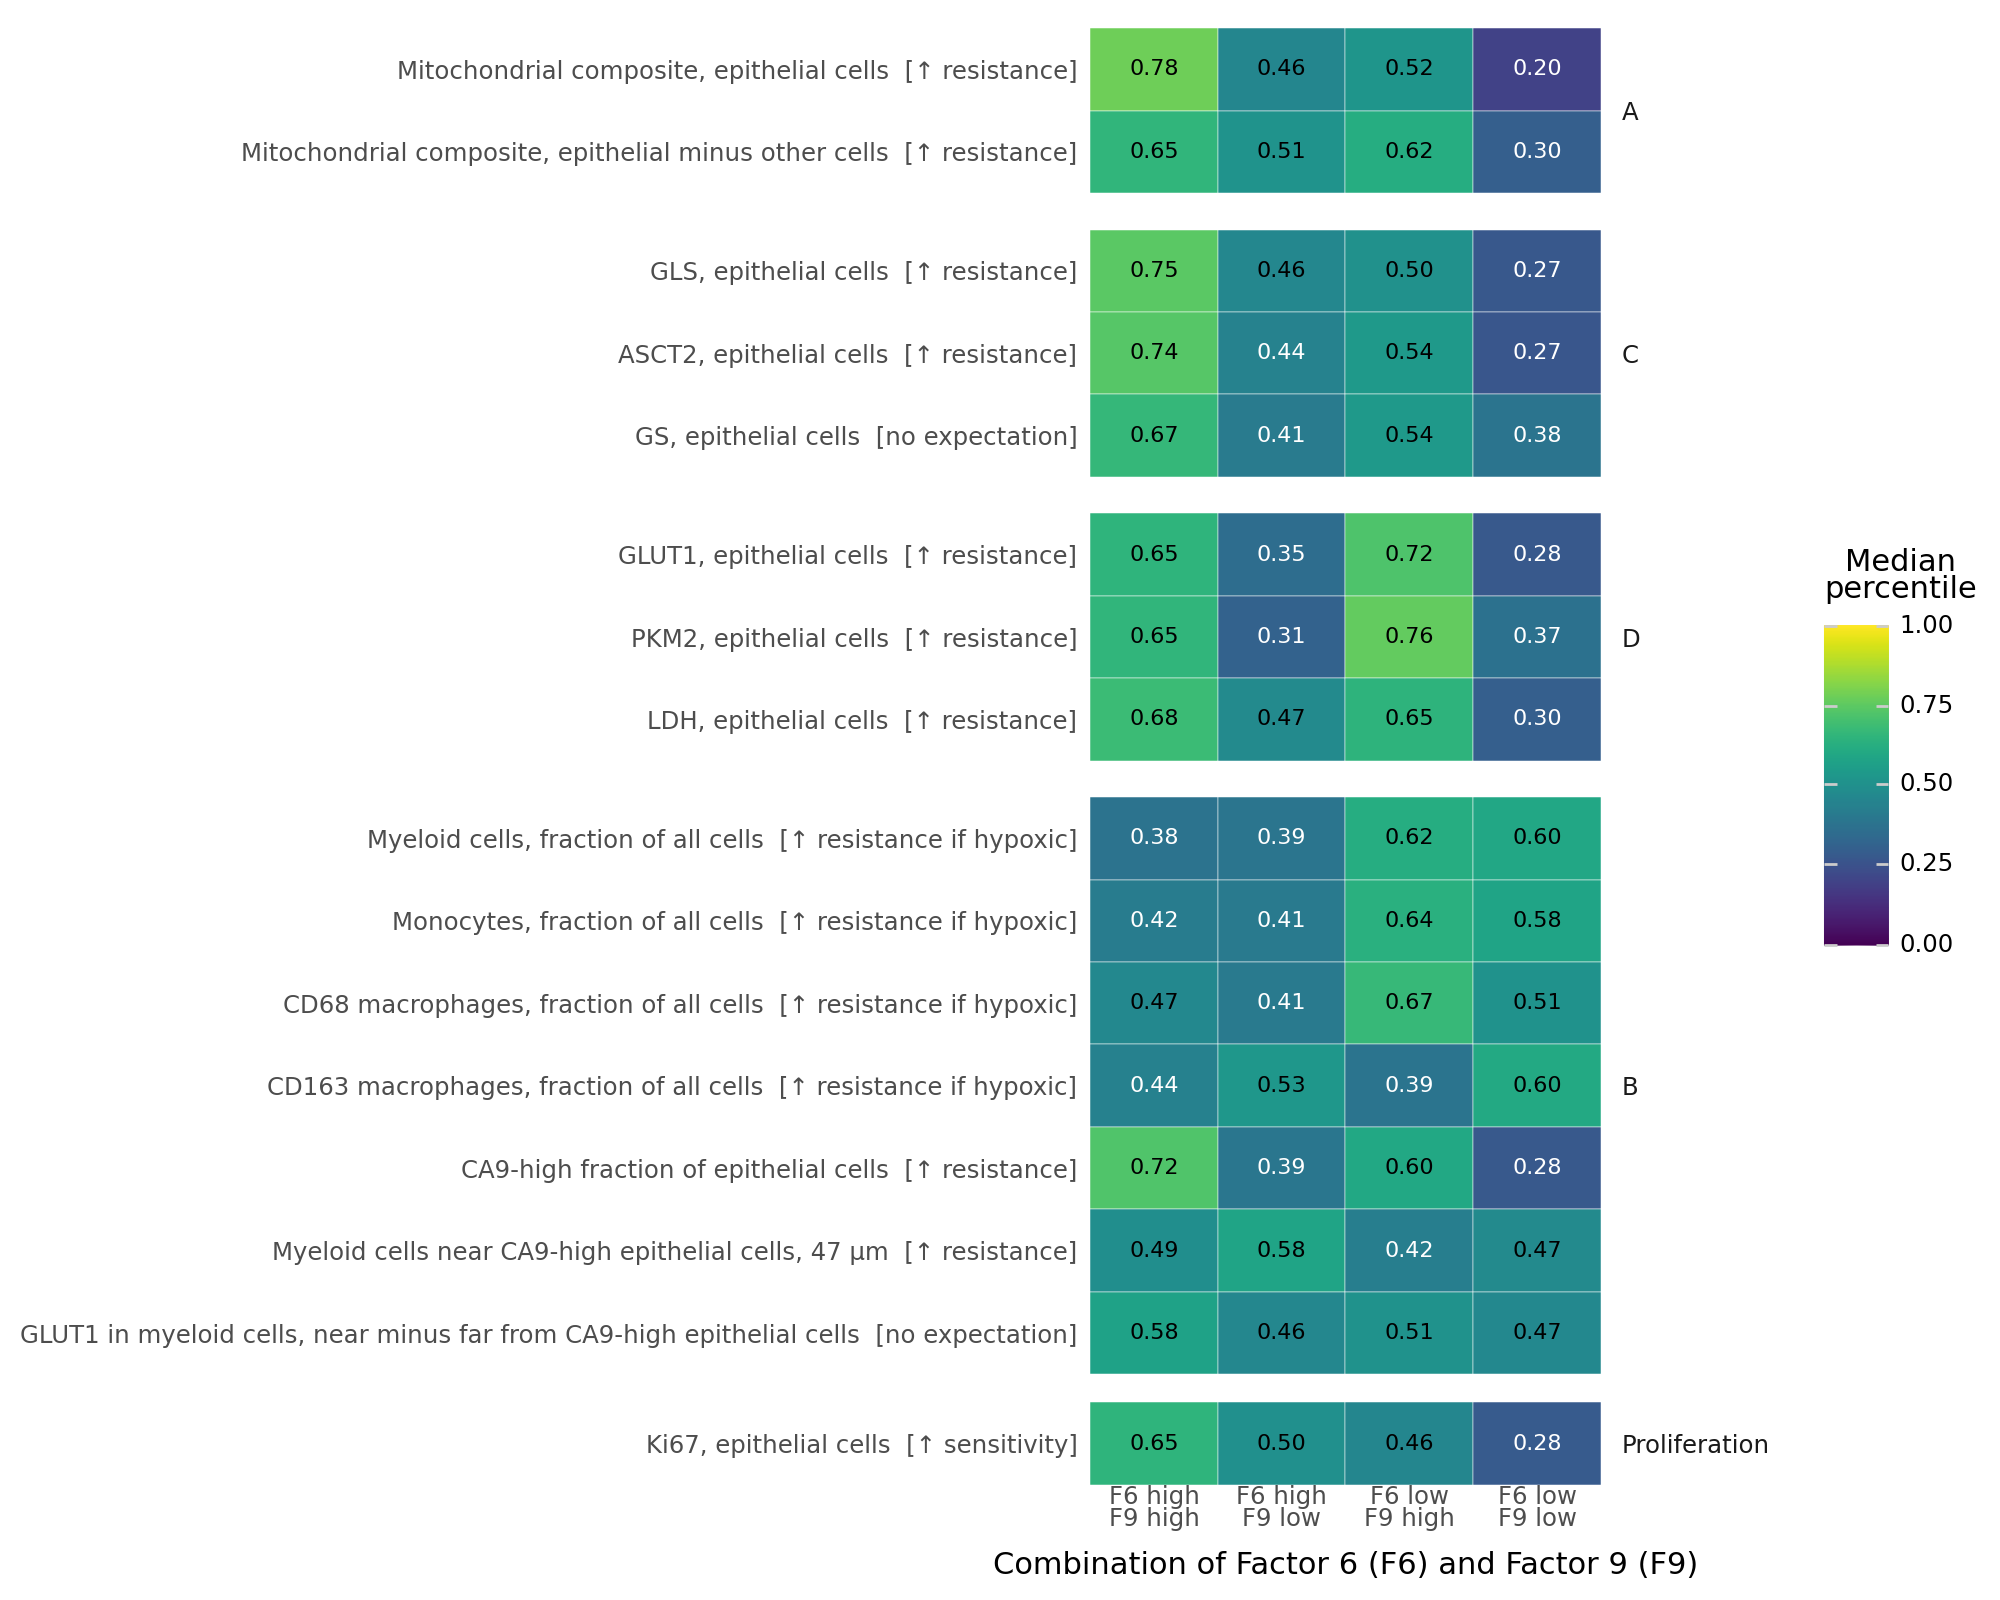

In [20]:
combination_names = {(True, True): "F6 high\nF9 high", (True, False): "F6 high\nF9 low",
                     (False, True): "F6 low\nF9 high", (False, False): "F6 low\nF9 low"}
combination_order = list(combination_names.values())
combination = pd.Series(pd.Categorical([combination_names[(a, b)] for a, b in high.values], categories=combination_order),
                        index=scores.index)
display(combination.value_counts().loc[combination_order].rename("patients").rename(index=lambda c: c.replace("\n", ", ")).to_frame())

profile_keys = ["A composite", "A composite contrast", "C GLS", "C ASCT2", "C GS", "D GLUT1", "D PKM2", "D LDH",
                "B1 Myeloid", "B1 Monocytes", "B1 CD68 macrophages", "B1 CD163 macrophages", "B2 CA9-high",
                f"B3 {radius_um[max(radii_px)]}", "B4", "Ki67"]
profile_keys = [k for k in profile_keys if k in readouts]
row_names = {k: f"{readout_info.loc[k, 'label']}  [{readout_info.loc[k, 'expected']}]" for k in profile_keys}
profile = readouts[profile_keys].rank(pct=True).groupby(combination, observed=True).median().T
profile_tests = pd.DataFrame({"p": [kruskal(*[readouts.loc[combination == c, k].dropna() for c in combination_order]).pvalue
                                    for k in profile_keys]}, index=[readout_info.loc[k, "label"] for k in profile_keys])
profile_tests["q (FDR)"] = multipletests(profile_tests.p, method="fdr_bh")[1]

profile_df = profile.rename_axis("readout").reset_index().melt(id_vars="readout", var_name="combination", value_name="percentile")
profile_df["process"] = pd.Categorical(profile_df.readout.map(readout_info.process), categories=["A", "C", "D", "B", "Proliferation"])
profile_df["label"] = pd.Categorical(profile_df.readout.map(row_names), categories=[row_names[k] for k in profile_keys][::-1])
profile_df["combination"] = pd.Categorical(profile_df.combination, categories=combination_order)

gp = (ggplot(profile_df, aes(x="combination", y="label", fill="percentile"))
      + geom_tile(color="white")
      + geom_text(aes(label="percentile", color="percentile < 0.45"), format_string="{:.2f}", size=8, show_legend=False)
      + scale_color_manual(values={True: "white", False: "black"})
      + scale_fill_cmap(cmap_name="viridis", limits=(0, 1), name="Median\npercentile")
      + facet_grid("process~.", scales="free_y", space="free_y")
      + labs(x="Combination of Factor 6 (F6) and Factor 9 (F9)", y="")
      + theme_classic()
      + theme(figure_size=(10, 8), axis_line=element_blank(), axis_ticks=element_blank(),
              strip_background=element_blank(), strip_text_y=element_text(angle=0)))
gp.save(figure_dir + "factor6_vs_factor9_profiles.pdf", verbose=False)
display(profile_tests.map("{:.2g}".format))
gp

The combinations differ in most epithelial and myeloid readouts. Reading the heatmap by column gives the profile of each combination:
- **F6 high, F9 high.** Epithelial cells rank high on all three kinds of machinery, mitochondrial, glutamine and glycolytic, and on Ki67 and the CA9-high fraction. Myeloid cells are fewer than in the median patient.
- **F6 high, F9 low.** Readouts close to or below the median throughout, with few myeloid cells.
- **F6 low, F9 high.** The most glycolytic machinery of the four, mitochondrial machinery near the median, and more myeloid cells, monocytes and CD68 macrophages above all.
- **F6 low, F9 low.** Low epithelial machinery, Ki67 and CA9-high fraction, and more myeloid cells, CD163 macrophages above all.

The localisation of myeloid cells near hypoxic epithelium and their GLUT1 hardly differ between combinations, as expected from section 5, where no factor followed them.

### Clinical context of Factors 6 and 9
`MOFACell.ipynb` found Factor 6 among the factors associated with pT, and Factor 9 among those associated with MSI. The half violins show these two distributions for reference, with the palettes of the earlier notebooks. They are not tested again.

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/plotnine/positions/position.py:232: PlotnineWarning: position_dodge requires non-overlapping x intervals


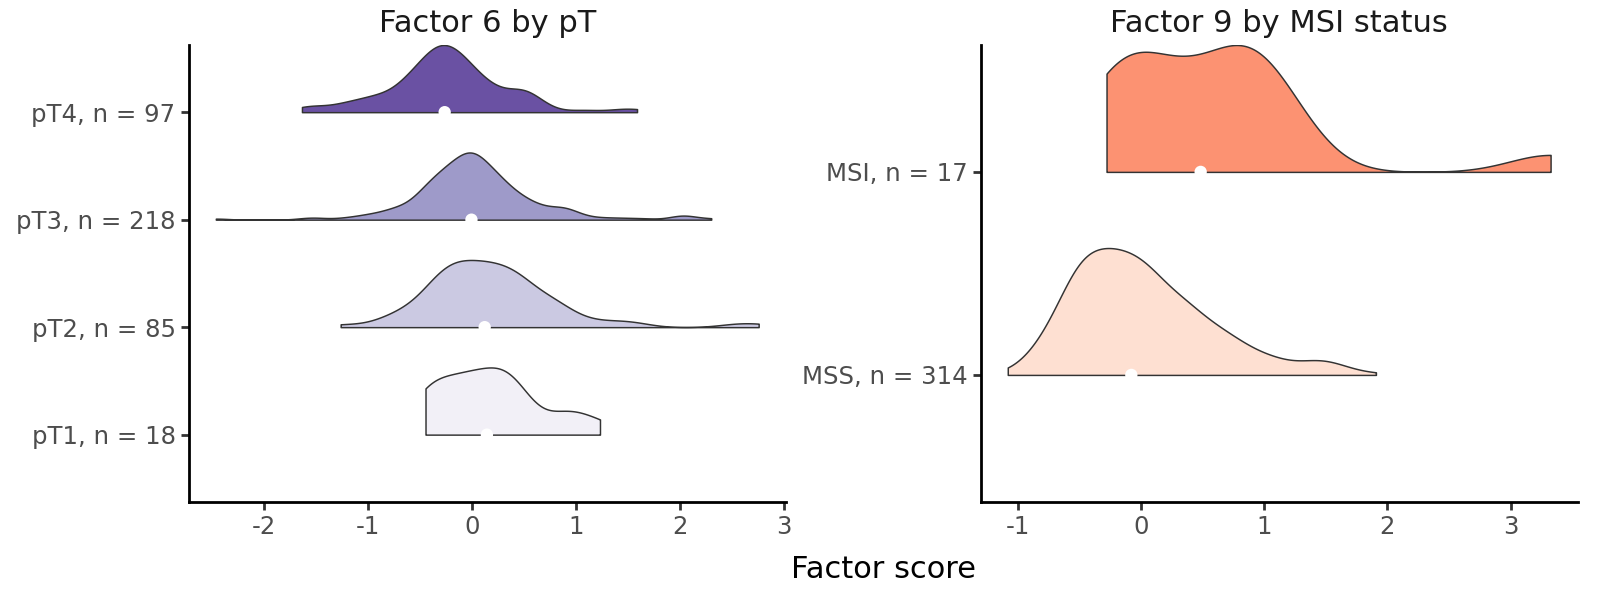

In [21]:
reference = pd.concat([
    pd.DataFrame({"panel": "Factor 6 by pT", "category": clinical.pT, "score": scores["Factor 6"]}),
    pd.DataFrame({"panel": "Factor 9 by MSI status", "category": clinical.MSI, "score": scores["Factor 9"]}),
]).dropna()
reference["category"] = pd.Categorical(reference.category.astype(str), categories=list(clinical_colors))
reference = reference.join(reference.groupby("category", observed=True).size().rename("n"), on="category")
reference["category_label"] = reference.category.astype(str) + ", n = " + reference.n.astype(str)
reference["category_label"] = pd.Categorical(reference.category_label,
                                          categories=reference.sort_values("category").category_label.unique())

gp = (ggplot(reference, aes(x="category_label", y="score"))
      + half_violins("category")
      + coord_flip()
      + facet_wrap("~panel", scales="free")
      + scale_fill_manual(values=clinical_colors)
      + labs(x="", y="Factor score")
      + theme_classic()
      + theme(figure_size=(8, 3), legend_position="none", strip_background=element_blank(),
              strip_text=element_text(size=11)))
gp.save(figure_dir + "factor6_pT_factor9_MSI.pdf", verbose=False)
gp

### Clinical annotations of each combination
The combinations are built from the factor scores, so testing their clinical annotations would repeat the associations of `MOFACell.ipynb`. The stacked bars describe them instead. The number above each bar is the number of annotated patients in the combination.

pT              pN          MSI    
                 pT1 pT2 pT3 pT4 pN0 pN1 pN2  MSS MSI
combination                                          
F6 high, F9 high   4  31  68  23  72  31  23  100   7
F6 high, F9 low    7  20  49   7  48  23  12   67   3
F6 low, F9 high    2  11  34  36  32  23  27   62   6
F6 low, F9 low     5  23  67  31  70  29  26   85   1

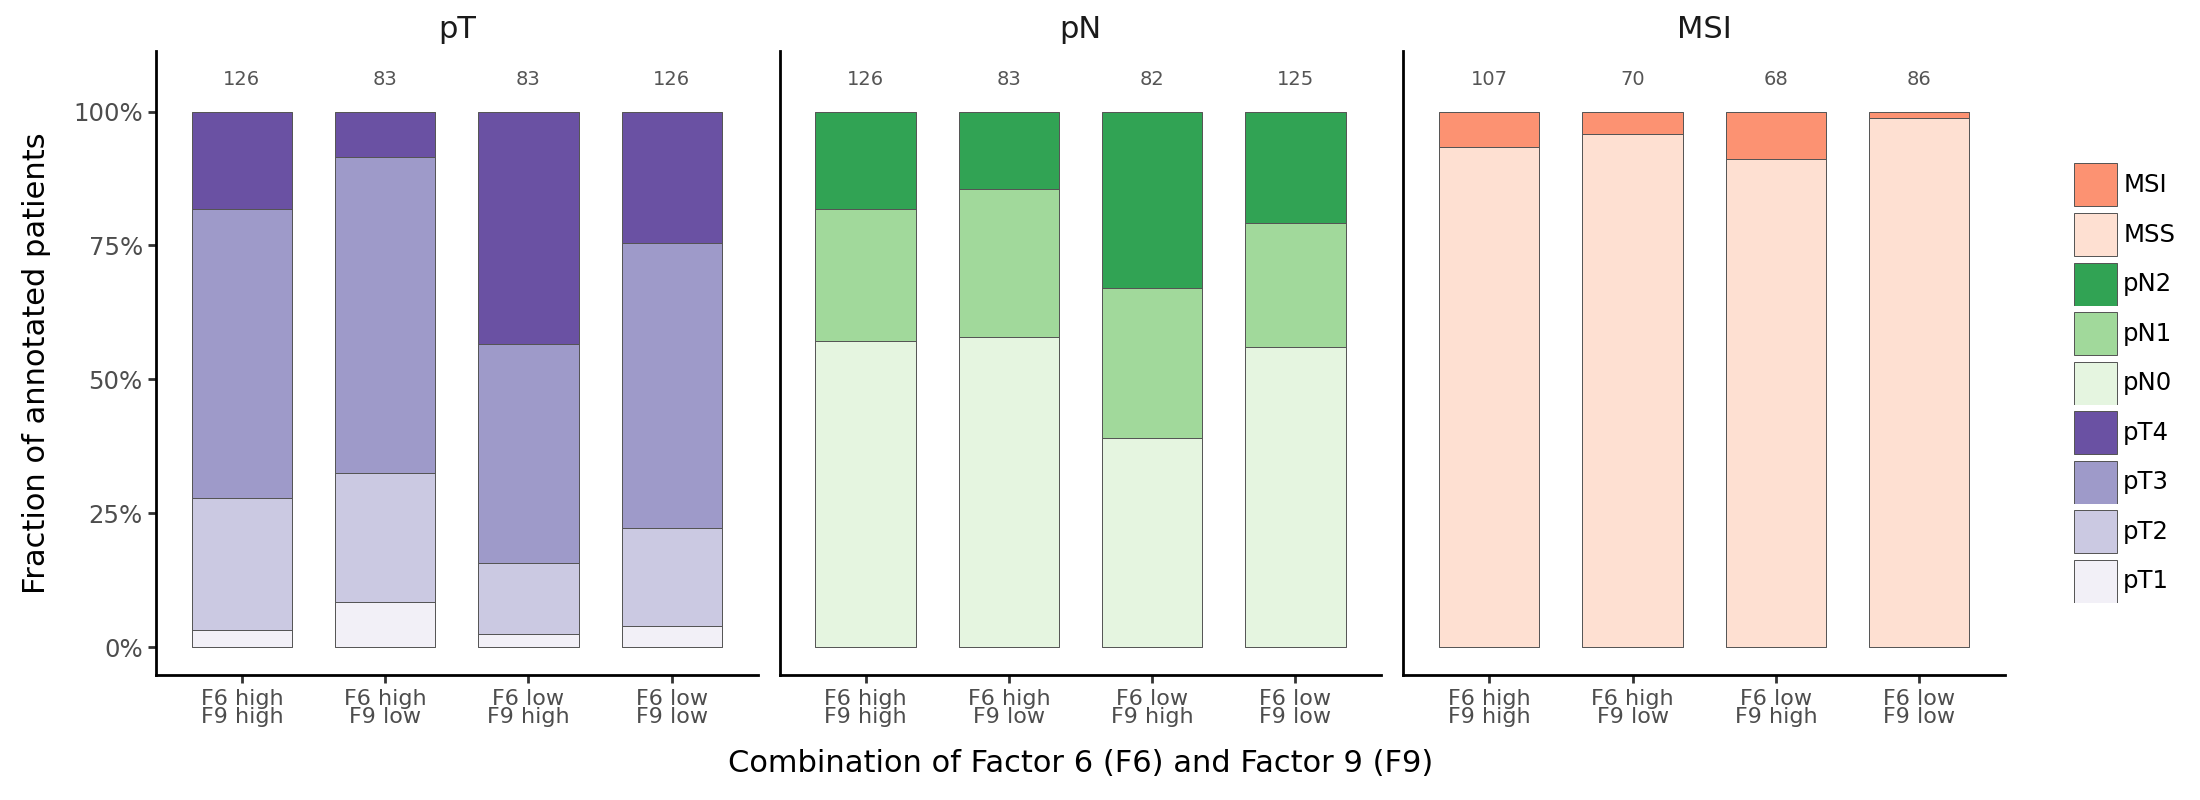

In [22]:
composition = []
for annotation in clinical:
    counts = pd.crosstab(combination, clinical[annotation])
    fractions = counts.div(counts.sum(axis=1), axis=0)
    long = fractions.rename_axis("combination").reset_index().melt(id_vars="combination", var_name="category", value_name="fraction")
    long["annotation"] = annotation
    long["n"] = long.combination.map(counts.sum(axis=1))
    composition.append(long)
composition = pd.concat(composition)
composition["annotation"] = pd.Categorical(composition.annotation, categories=list(clinical))
composition["category"] = pd.Categorical(composition.category.astype(str), categories=list(clinical_colors)[::-1])
composition["combination"] = pd.Categorical(composition.combination, categories=combination_order)
totals = composition.drop_duplicates(["annotation", "combination"])

gp = (ggplot(composition, aes(x="combination", y="fraction", fill="category"))
      + geom_col(width=0.7, color="#555555", size=0.2)
      + geom_text(aes(x="combination", y=1.06, label="n"), data=totals, inherit_aes=False, size=7, color="#555555")
      + facet_wrap("~annotation", ncol=3)
      + scale_fill_manual(values=clinical_colors)
      + scale_y_continuous(labels=lambda breaks: [f"{b:.0%}" for b in breaks], breaks=[0, 0.25, 0.5, 0.75, 1])
      + labs(x="Combination of Factor 6 (F6) and Factor 9 (F9)", y="Fraction of annotated patients", fill="")
      + theme_classic()
      + theme(figure_size=(11, 4), axis_text_x=element_text(size=8), strip_background=element_blank(),
              strip_text=element_text(size=11)))
gp.save(figure_dir + "factor6_vs_factor9_clinical.pdf", verbose=False)
display(pd.concat({a: pd.crosstab(combination, clinical[a]) for a in clinical}, axis=1).rename_axis("combination").rename(index=lambda c: c.replace("\n", ", ")))
gp

The combinations inherit the clinical associations of the two factors. The F6 low combinations hold more pT4 tumours, and the few MSI tumours fall mostly in the F9 high combinations. MSI tumours are too few to compare the combinations statistically.

## 7. Therapeutic interpretation
The combinations of Factors 6 and 9 describe the state of the tissue at resection. Each measured process corresponds to a mechanism that changes 5-FU response in experimental models, so each combination suggests which mechanisms are worth studying in that kind of tumour. These are hypotheses. Drug response, DPD and metabolic flux are not measured, and no combination predicts benefit from 5-FU.

Two kinds of interaction between the processes matter:
- **Redundancy.** Mitochondrial, glutamine and glycolytic machinery all act inside the epithelial cell, on its survival under 5-FU. Where all three are high, blocking one route could be compensated by the others, so a single metabolic inhibitor might add little.
- **Epistasis.** Myeloid DPD acts upstream, on how much active drug reaches the epithelial cells. Where exposure is limited, the survival mechanisms of the epithelial cells matter less. Their effect would only show once exposure is restored, for example with the DPD inhibitor gimeracil or by targeting macrophages through CSF-1R.

| Combination | Measured features | Hypothesis for 5-FU | Clinical context | Not supported by these data |
|---|---|---|---|---|
| F6 high, F9 high | High mitochondrial, glutamine and glycolytic machinery, Ki67 and CA9-high fraction. Fewer myeloid cells | Several survival mechanisms side by side, so redundancy is the main concern. Combinations that target more than one metabolic route would be the ones to test. High proliferation favours 5-FU activity, while MSI, more frequent here, works against it | Less advanced than the F6 low combinations. More MSI tumours | Greater resistance than other tumours, or metabolic flexibility shown by flux |
| F6 high, F9 low | Machinery near or below the median. Few myeloid cells | The fewest measured features linked to reduced 5-FU response. A candidate context in which 5-FU meets fewer obstacles | Least advanced | Sensitivity to 5-FU |
| F6 low, F9 high | The most glycolytic machinery. More myeloid cells, mostly monocytes and CD68 macrophages. CA9-high epithelial cells present | Two mechanisms at different steps could coincide: drug breakdown by myeloid cells upstream, and glycolysis-supported survival downstream. By epistasis, the myeloid context would come first, and glycolysis would matter once exposure is restored | Most advanced. These patients are the most likely to receive adjuvant 5-FU. More MSI tumours | DPD-mediated resistance, since DPD is not measured and myeloid cells are not specifically near hypoxic epithelium |
| F6 low, F9 low | Low epithelial machinery and Ki67. Few CA9-high epithelial cells. More myeloid cells, mostly CD163 macrophages | Little support for mitochondrial adaptation. The myeloid cells are present, but without the hypoxia under which macrophages raise DPD. Low proliferation could limit 5-FU activity on its own | Intermediate | Response to 5-FU in either direction |

Lower Factor 6 goes with higher pT. In the tumours most likely to receive adjuvant 5-FU, the measured contexts lean towards less epithelial mitochondrial machinery and more myeloid cells. An analysis of epithelial cells alone would see little intrinsic resistance there. It would miss the myeloid compartment and, in F6 low with F9 high tumours, the glycolytic machinery.

Higher Factor 9 goes with MSI. MSI tumours lack mismatch repair, which makes epithelial cells tolerate 5-FU, and MSI colon cancers drew no benefit from adjuvant 5-FU alone. In the F9 high combinations, this tolerance would add to the high metabolic machinery of the epithelial cells, another case of redundancy: several features linked to reduced 5-FU response in the same tumours. Factor 9 is not a surrogate for MSI, since most F9 high tumours are MSS. In those, the metabolic machinery remains the main measured feature. The cohort has too few MSI tumours to tell whether their metabolic profile differs from that of MSS tumours with similar factor scores.

None of the combinations is defined by where myeloid cells sit relative to hypoxic epithelium. No factor captures it, and across patients myeloid cells show no specific attraction to hypoxic epithelium. Testing the DPD hypothesis would need myeloid cells in CA9-high regions to be studied within tumours.

## Export

In [23]:
readouts.join(scores).join(combination.str.replace("\n", ", ").rename("combination")).rename_axis("patient").to_csv(
    output_dir + "process_readouts.csv")
readout_info.to_csv(output_dir + "process_readout_definitions.csv")
map_df.drop(columns=["label", "factor_label"]).to_csv(output_dir + "factor_readout_correlations.csv", index=False)
agreement.to_csv(output_dir + "marker_agreement.csv", index=False)
composition.to_csv(output_dir + "factor6_factor9_clinical_composition.csv", index=False)